# Semester Project · Deliverable 2

## Reading Water-Meter Readings from Photographs

This project explores how machine learning can help read an analog water meter from a photograph. The system is designed to find the number display, make sure it is the right way up, and recognise the digits.

**Dataset:** The notebook uses 1,244 water-meter photographs. After checking the data, 1,208 images were suitable for digit reading.

**Goal:** Given a photograph, the system should return the meter reading, for example `00595.825 m³`.

**Learning approach:** This is a supervised learning project because the photographs come with the correct readings and marked display areas. The models learn from these examples and are tested on photographs they have not seen before.

**Main finding:** Random Forest achieved the strongest individual-digit and cross-validation results among the digit-reading models tested. However, SVM achieved a higher test score for complete readings. The results are still too low for automatic billing, so the selected model should be treated as a promising starting point rather than a finished solution.

---

## Project stages

1. **Understand and clean the data:** Check the photographs, readings and marked display areas.
2. **Prepare the photographs:** Find the display, crop it and correct its direction.
3. **Train and compare models:** Test different ways of recognising the digits.
4. **Review the results:** Compare how often the models read individual digits, whole-number readings and complete readings correctly.
5. **Check the full process:** Review how the stages work together and how long they take.

## Models used

- **U-Net:** Finds the display area in the photograph.
- **Orientation CNN:** Checks whether the display is upright or upside down.
- **Random Forest:** Selected as the main digit-reading model based on its strong individual-digit and cross-validation results.
- **Other models:** CNN, SVM, Logistic Regression and other methods are kept in the comparison so their results can be reported fairly.

**Important:** The current test and timing section still use the original CNN reader. Random Forest has been compared as a digit reader, but it has not yet been tested as part of the complete photo-to-reading process. The notebook states this distinction wherever the results are discussed.

---

## What is new in this version

| Area | Change |
|---|---|
| **Google Drive / Colab** | One setup cell mounts Drive, finds `water_meter_dataset` (folder or `.zip`), and copies it to Colab's local disk so training is not slowed down by Drive reads. |
| **Display direction** | About 3-4 % of the crops are upside down in the raw data. They are now detected (red decimal wheels must sit on the right) and corrected **before** any digit reader is trained. In the earlier version the readers were trained before the orientation step, so they saw upside-down crops. |
| **Digit annotations** | The digit boxes no longer depend on hand-checking ~10 000 rows. Boxes are generated automatically and exported as review sheets (green boxes + red labels) so you can spot-check them. The only automatic check is a blank-slot test, which almost every photograph passes, so the review sheets are the real safeguard. Row status is recorded in the `verified` column (`1` = checked by a person, `2` = passed the blank-slot test only). |
| **Fair comparison** | The single-digit CNN is tested on the **same held-out photographs** as the Part 4 models, so the numbers can be compared directly. |
| **End-to-end test** | Part 5 now contains a real photo-to-reading test (U-Net → crop → orientation → reader) with timing per stage, for both the original reader and the single-digit CNN. |
| **Smaller fixes** | Removed the per-image printout in the mask check, fixed a percentage-format bug in Observation 2, and added switches to skip the slowest baseline experiments. |

> **Reporting rule:** results are only claimed for cells that have actually been run. Digit labels come from the supplied meter readings, and digit boxes are automatic unless `verified = 1`.

In [ ]:
%pip -q install scikit-image seaborn

import os, zipfile, shutil
from pathlib import Path

print('Dependencies installed.')


Dependencies installed.


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 1.1  Connect Google Drive and prepare the dataset
# ------------------------------------------------------------------
# Upload the dataset to Google Drive first. Either of these works:
#   MyDrive/water_meter_dataset/            (containing data.csv, images/, masks/)
#   MyDrive/water_meter_dataset*.zip        (the zip you downloaded; it is unzipped automatically)
# If you used a different folder name, change DRIVE_FOLDER below.
# ------------------------------------------------------------------
import os, glob, shutil, zipfile
from pathlib import Path

DRIVE_FOLDER = '/content/drive/MyDrive/water_meter_dataset'
LOCAL_ROOT   = Path('/content/water_meter_dataset')      # fast local copy
DRIVE_OUT    = Path('/content/drive/MyDrive/water_meter_outputs')   # results are saved here at the end

def is_dataset_root(p):
    p = Path(p)
    return (p / 'data.csv').exists() and (p / 'images').is_dir() and (p / 'masks').is_dir()

def find_root(base, max_depth=3):
    base = Path(base)
    if not base.exists():
        return None
    if is_dataset_root(base):
        return base
    for depth in range(1, max_depth + 1):
        for hit in sorted(glob.glob(str(base / '/'.join(['*'] * depth) / 'data.csv'))):
            if is_dataset_root(Path(hit).parent):
                return Path(hit).parent
    return None

IN_COLAB = Path('/content').exists()
if IN_COLAB and not os.path.ismount('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

if is_dataset_root(LOCAL_ROOT):
    src = LOCAL_ROOT
    print('Using the local copy that is already in this session:', src)
else:
    src = find_root(DRIVE_FOLDER) or find_root('/content/drive/MyDrive')
    if src is None:                                   # maybe only the zip was uploaded
        zips = sorted(set(glob.glob('/content/drive/MyDrive/water_meter_dataset*.zip')
                          + glob.glob('/content/drive/MyDrive/*/water_meter_dataset*.zip')))
        if zips:
            print('Unzipping', zips[0], '...')
            with zipfile.ZipFile(zips[0]) as z:
                z.extractall('/content/_unzipped')
            src = find_root('/content/_unzipped')
    if src is None:
        raise FileNotFoundError(
            'Could not find the dataset. Upload the folder water_meter_dataset (data.csv, images/, masks/) '
            'or its .zip to MyDrive, or edit DRIVE_FOLDER in this cell.')
    if str(src).startswith('/content/drive'):
        print('Copying dataset from Drive to local disk (one-off, about a minute)...')
        shutil.copytree(src, LOCAL_ROOT, dirs_exist_ok=True)
        src = LOCAL_ROOT

DATA_ROOT = Path(src)
CSV_PATH  = DATA_ROOT / 'data.csv'
IMAGE_DIR = DATA_ROOT / 'images'
MASK_DIR  = DATA_ROOT / 'masks'

n_img, n_msk = len(list(IMAGE_DIR.iterdir())), len(list(MASK_DIR.iterdir()))
print('Dataset root:', DATA_ROOT)
print(f'Images: {n_img} | Masks: {n_msk}')
assert n_img > 0 and n_msk > 0, 'images/ or masks/ is empty'

Mounted at /content/drive
Copying dataset from Drive to local disk (one-off, about a minute)...
Dataset root: /content/water_meter_dataset
Images: 1244 | Masks: 1244


# Part 1 · Machine Learning Approach

## What does the system need to do?

The system receives a photograph of a water meter and should return the number shown on its display. The dataset includes the correct reading and a marked area showing where the display is located.

Because the correct answers are provided with the photographs, the project uses **supervised learning**. In simple terms, the models learn from examples that already have answers.

## Finding the display

We use **U-Net** to find the part of the photograph that contains the meter reading. The system then crops that area and straightens it so the digits are easier to read.

## Checking the direction

Some photographs may show the display upside down. A small **CNN** checks whether the display is upright or upside down so it can be corrected before the digits are read.

## Recognising the digits

The original notebook compares CNN models with Random Forest, SVM and other traditional machine-learning methods. The original comparison is retained as a baseline experiment.

For the improved version, the project continues with **CNN as the preferred digit-recognition approach**. The next stage changes the recognition task from predicting all eight positions from one display image to classifying individually proposed digit crops. This is a new experiment; its performance must be measured independently after the digit annotations have been manually verified.

## Why this is supervised learning

Each training photograph has a known reading. The model compares its predictions with those correct answers and learns from the differences. It can then make predictions for new photographs.


In [ ]:
import os, re, ast, json, glob, math, time, random, gc, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from skimage.feature import hog
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

# configuration
SEED = 42
DATA_ROOT = globals().get('DATA_ROOT', None)
FAST_DEV = False
# RAM-SAFE DEFAULTS: Part 4 reuses the CNN trained in Part 3 instead of
# fitting nine additional readers. The two optional U-Net ablations are skipped.
RUN_BASELINE_COMPARISON = False
RUN_SEG_ABLATIONS = False
ALLOW_AUTO_QA = True             # Part 7: also train on rows that passed the automatic check (verified=2)
DIGIT_EPOCHS = 8 if FAST_DEV else 40
EPOCHS = {'seg': 3 if FAST_DEV else 20, 'read': 3 if FAST_DEV else 20, 'orient': 3 if FAST_DEV else 15}
BATCH = {'seg': 4, 'read': 16, 'orient': 16}  # smaller batches reduce peak RAM/VRAM
SEG_SIZE = 256
CROP_H, CROP_W = 64, 256
N_DIGITS = 8
CROP_CLAHE = True
NEAR_DUP_BITS = 4
POS_LABELS = ['10^4', '10^3', '10^2', '10^1', '10^0', '10^-1', '10^-2', '10^-3']

random.seed(SEED); np.random.seed(SEED)

def find_dataset_root():
    cands = [Path(p).parent for p in glob.glob('/content/**/data.csv', recursive=True)]
    cands += [Path(p).parent for p in glob.glob('/kaggle/input/**/data.csv', recursive=True)]
    cands += [Path(p) for p in ['./WaterMeters', '../WaterMeters', '/content/WaterMeters']]
    for r in cands:
        if (r / 'data.csv').exists() and (r / 'images').is_dir() and (r / 'masks').is_dir():
            return r
    return None

if DATA_ROOT is None:
    DATA_ROOT = find_dataset_root()
WORK_DIR = Path('/content/outputs') if Path('/content').exists() else (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('./outputs'))
WORK_DIR.mkdir(parents=True, exist_ok=True)
USE_SYNTHETIC = DATA_ROOT is None
if USE_SYNTHETIC and Path('/content').exists():
    raise FileNotFoundError('Real dataset not found in Google Colab. Run the dataset upload cell and verify data.csv, images/, and masks/ before continuing.')
print('Dataset root :', DATA_ROOT if not USE_SYNTHETIC else 'NOT FOUND -> synthetic demo data will be generated')

Dataset root : /content/water_meter_dataset


# Part 2 · Data Cleaning

Before training, the dataset is checked to make sure the photographs, readings and display markings are usable.

The checks look for:
- Repeated photographs.
- Missing photographs or display masks.
- Missing or invalid readings.
- Readings that do not match their filenames.
- Incorrect or unclear display markings.

The notebook also checks whether the photographs and masks can be opened. Records that fail the checks are removed so they do not affect training.

The cleaning results are shown in the tables produced by the cells below.


In [ ]:
def parse_polygon(loc):
    try:
        d = ast.literal_eval(loc) if isinstance(loc, str) else loc
        pts = np.array([[p['x'], p['y']] for p in d['data']], dtype=np.float64)
        return pts if pts.ndim == 2 and pts.shape[1] == 2 else None
    except Exception:
        return None

def poly_area(p):
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def name_value(n):
    m = re.search(r'value_(\d+)_(\d+)', str(n))
    return float(f'{m.group(1)}.{m.group(2)}') if m else np.nan

def find_mask(name):
    stem = Path(name).stem
    for cand in [name, stem + '.jpg', stem + '.png']:
        if (MASK_DIR / cand).exists():
            return str(MASK_DIR / cand)
    return None

def value_to_digits(v):
    n = int(round(float(v) * 1000)); s = f'{n:0{N_DIGITS}d}'
    return np.array([int(c) for c in s], dtype=np.int64)

def digits_to_value(D):
    D = np.asarray(D, dtype=np.int64); ok = (D >= 0).all(-1)
    v = (np.clip(D, 0, 9) * (10 ** np.arange(N_DIGITS - 1, -1, -1))).sum(-1) / 1000.0
    return np.where(ok, v, np.nan)

def fmt_reading(d):
    if (np.asarray(d) < 0).any(): return 'FAIL'
    s = ''.join(str(int(x)) for x in d); return s[:5] + '.' + s[5:]

def window_geometry(mask_bin, min_area=30):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask_bin.astype(np.uint8), connectivity=8)
    if n <= 1: return None
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    if st[k, cv2.CC_STAT_AREA] < min_area: return None
    pts = cv2.findNonZero((lab == k).astype(np.uint8))
    hull = cv2.convexHull(pts)
    rect = cv2.minAreaRect(hull)
    box = cv2.boxPoints(rect)
    e1, e2 = box[1] - box[0], box[2] - box[1]
    n1, n2 = np.linalg.norm(e1), np.linalg.norm(e2)
    d, L, S = (e1 / n1, n1, n2) if n1 >= n2 else (e2 / n2, n2, n1)
    if abs(d[0]) >= abs(d[1]):
        if d[0] < 0: d = -d
    elif d[1] < 0:
        d = -d
    return dict(center=(float(rect[0][0]), float(rect[0][1])), d=d.astype(np.float32), L=float(L), S=float(max(S, 1.0)),
                angle=float(np.degrees(np.arctan2(d[1], d[0]))))

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 8))
def apply_clahe(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB); lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def warp_window(img_rgb, geo, out_hw=(CROP_H, CROP_W), pad_l=0.04, pad_s=0.18, clahe=CROP_CLAHE):
    H, W = out_hw
    c = np.array(geo['center'], np.float32); d = np.array(geo['d'], np.float32); nrm = np.array([-d[1], d[0]], np.float32)
    hl, hs = geo['L'] * (1 + 2 * pad_l) / 2, geo['S'] * (1 + 2 * pad_s) / 2
    src = np.stack([c - d * hl - nrm * hs, c + d * hl - nrm * hs, c + d * hl + nrm * hs, c - d * hl + nrm * hs]).astype(np.float32)
    k = 2
    dst = np.array([[0, 0], [W * k - 1, 0], [W * k - 1, H * k - 1], [0, H * k - 1]], np.float32)
    big = cv2.warpPerspective(img_rgb, cv2.getPerspectiveTransform(src, dst), (W * k, H * k), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    out = cv2.resize(big, (W, H), interpolation=cv2.INTER_AREA)
    return apply_clahe(out) if clahe else out

def dhash_bits(gray):
    s = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    return (s[:, 1:] > s[:, :-1]).flatten().astype(np.int8)

cleaning_log = []
def log_step(step, check, flagged, action, remaining):
    cleaning_log.append(dict(step=step, check=check, flagged=int(flagged), action=action, rows_remaining=int(remaining)))
    print(f'[{step}] {check}: flagged {int(flagged)} -> {action}; {int(remaining)} rows remain')

In [ ]:
import pandas as pd

# Reads the raw dataset first
raw = pd.read_csv(CSV_PATH)
df = raw.copy()

duplicates = df.duplicated(subset=['photo_name'], keep='first')
df = df.loc[~duplicates].copy()

log_step(
    'C1',
    'Repeated photographs',
    duplicates.sum(),
    'Removed extra copies',
    len(df)
)

# Checks that every photograph has a matching image and mask
df['img_path'] = df['photo_name'].map(lambda n: str(IMAGE_DIR / n))
df['mask_path'] = df['photo_name'].map(find_mask)

missing = ~df['img_path'].map(os.path.exists) | df['mask_path'].isna()
df = df.loc[~missing].copy()

log_step(
    'C2',
    'Missing photographs or masks',
    missing.sum(),
    'Removed incomplete records',
    len(df)
)

# Checks if the water meter readings are valid
df['value'] = pd.to_numeric(df['value'], errors='coerce')

bad_val = (
    df['value'].isna()
    | (df['value'] < 0)
    | (df['value'] >= 10 ** (N_DIGITS - 3))
)

df = df.loc[~bad_val].copy()

log_step(
    'C3a',
    'Invalid water readings',
    bad_val.sum(),
    'Removed invalid readings',
    len(df)
)

# Checks if the reading matches the photograph's filename
df['value_from_name'] = df['photo_name'].map(name_value)

mism = (df['value'] - df['value_from_name']).abs() > 1e-6
df = df.loc[~mism].copy()

log_step(
    'C3b',
    'Readings that do not match their filenames',
    mism.sum(),
    'Removed records with conflicting readings',
    len(df)
)

# Checks if the marked reading window is valid
df['poly'] = df['location'].map(parse_polygon)

def poly_ok(p):
    return (
        p is not None
        and len(p) >= 3
        and np.isfinite(p).all()
        and poly_area(p) > 1e-4
        and p.min() > -0.02
        and p.max() < 1.02
    )

bad_poly = ~df['poly'].map(poly_ok)

df = df.loc[~bad_poly].copy()
df['poly'] = df['poly'].map(lambda p: np.clip(p, 0, 1))
df = df.reset_index(drop=True)

log_step(
    'C4',
    'Incorrect or unclear reading-window markings',
    bad_poly.sum(),
    'Removed invalid markings',
    len(df)
)

# Shows the cleaning results
cleaning_summary = pd.DataFrame(cleaning_log)

display(cleaning_summary)

[C1] Repeated photographs: flagged 0 -> Removed extra copies; 1244 rows remain
[C2] Missing photographs or masks: flagged 0 -> Removed incomplete records; 1244 rows remain
[C3a] Invalid water readings: flagged 0 -> Removed invalid readings; 1244 rows remain
[C3b] Readings that do not match their filenames: flagged 0 -> Removed records with conflicting readings; 1244 rows remain
[C4] Incorrect or unclear reading-window markings: flagged 0 -> Removed invalid markings; 1244 rows remain


,step,check,flagged,action,rows_remaining
0,C1,Repeated photographs,0,Removed extra copies,1244
1,C2,Missing photographs or masks,0,Removed incomplete records,1244
2,C3a,Invalid water readings,0,Removed invalid readings,1244
3,C3b,Readings that do not match their filenames,0,Removed records with conflicting readings,1244
4,C4,Incorrect or unclear reading-window markings,0,Removed invalid markings,1244


In [ ]:
def read_aligned(img_path, mask_path):
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE); im = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if im is None or m is None: return None, None, 'unreadable'
    fix = 'none'
    if im.shape[:2] != m.shape[:2]:
        im2 = cv2.imread(img_path, cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
        if im2 is not None and im2.shape[:2] == m.shape[:2]: im, fix = im2, 'ignore_exif'
        else: return None, None, 'shape_mismatch'
    return im, m, fix

def extract_record(row):
    im, m, fix = read_aligned(row['img_path'], row['mask_path'])
    if im is None: return None, fix
    H, W = im.shape[:2]
    binm = (m > 127).astype(np.uint8)
    area_frac = float(binm.mean())
    if area_frac < 2e-4: return None, 'empty_mask'
    pm = np.zeros((H, W), np.uint8)
    cv2.fillPoly(pm, [np.round(row['poly'] * [W - 1, H - 1]).astype(np.int32)], 1)
    iou = float((pm & binm).sum() / max((pm | binm).sum(), 1))
    geo = window_geometry(binm)
    if geo is None: return None, 'no_window'
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    img256 = cv2.resize(rgb, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)
    m256 = (cv2.resize(binm * 255, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA) > 127).astype(np.uint8)
    g = cv2.cvtColor(img256, cv2.COLOR_RGB2GRAY)
    ang = geo['angle']; a = abs(ang)
    orient = 'horizontal' if a <= 30 else ('vertical' if 60 <= a <= 120 else 'diagonal')
    meta = dict(H=H, W=W, exif_fix=fix, area_frac=area_frac, poly_mask_iou=iou, L=geo['L'], S=geo['S'], aspect=geo['L'] / geo['S'],
                angle=ang, orient=orient, cx=geo['center'][0] / W, cy=geo['center'][1] / H, n_poly_pts=len(row['poly']),
                brightness=float(g.mean()), contrast=float(g.std()), sharpness=float(cv2.Laplacian(g, cv2.CV_64F).var()))
    return dict(meta=meta, img256=img256, m256=m256, crop=warp_window(rgb, geo), bits=dhash_bits(g)), 'ok'

recs, fail_reasons = [], {}
for i, row in tqdm(list(df.iterrows()), desc='reading photos'):
    r, why = extract_record(row)
    if r is None: fail_reasons[why] = fail_reasons.get(why, 0) + 1; recs.append(None)
    else: recs.append(r)
ok = np.array([r is not None for r in recs])
for why, c in fail_reasons.items():
    log_step('C5', f'pixel check failed: {why}', c, 'drop', len(df) - sum(fail_reasons.values()))
df = df.loc[ok].reset_index(drop=True); recs = [r for r in recs if r is not None]
ds = pd.concat([df[['photo_name', 'value', 'img_path', 'mask_path']].reset_index(drop=True), pd.DataFrame([r['meta'] for r in recs])], axis=1)
IMG256 = np.stack([r['img256'] for r in recs]); MASK256 = np.stack([r['m256'] for r in recs])
CROPS_RAW = np.stack([r['crop'] for r in recs]); BITS = np.stack([r['bits'] for r in recs]).astype(np.float32)
del recs; gc.collect()

def apply_keep(keep):
    global ds, IMG256, MASK256, CROPS_RAW, BITS
    keep = np.asarray(keep, bool)
    ds = ds.loc[keep].reset_index(drop=True); IMG256, MASK256, CROPS_RAW, BITS = IMG256[keep], MASK256[keep], CROPS_RAW[keep], BITS[keep]
bad_iou = (ds['poly_mask_iou'] < 0.5).values
if bad_iou.mean() < 0.10:
    apply_keep(~bad_iou); log_step('C5b', 'polygon-vs-mask IoU < 0.5 (annotation disagrees with itself)', bad_iou.sum(), 'drop', len(ds))
else:
    print(f'WARNING: {bad_iou.mean():.0%} of images have polygon/mask IoU<0.5 -> systematic; KEEPING them (masks are the primary label).')
    log_step('C5b', 'polygon-vs-mask IoU < 0.5 (systematic)', bad_iou.sum(), 'keep + warn', len(ds))
print('EXIF alignment fixes applied:', int((ds['exif_fix'] != 'none').sum()))

reading photos:   0%|          | 0/1244 [00:00<?, ?it/s]

[C5b] polygon-vs-mask IoU < 0.5 (annotation disagrees with itself): flagged 0 -> drop; 1244 rows remain
EXIF alignment fixes applied: 0


In [ ]:
# Inspect the image and mask arrays before training the U-Net
print("IMAGE AND MASK DIAGNOSTICS")
print("-" * 40)
print("Images:", IMG256.shape, IMG256.dtype, "| range", IMG256.min(), "to", IMG256.max())
print("Masks :", MASK256.shape, MASK256.dtype, "| unique values", np.unique(MASK256))

fg = MASK256.reshape(len(MASK256), -1).mean(1) * 100
print(f"\nForeground (display window) share of each 256x256 mask:")
print(f"  min {fg.min():.2f}% | median {np.median(fg):.2f}% | max {fg.max():.2f}%")
tiny = int((fg < 0.1).sum())
print(f"  masks under 0.1% of the image: {tiny}" + ("  <- check these" if tiny else ""))

IMAGE AND MASK DIAGNOSTICS
----------------------------------------
Images: (1244, 256, 256, 3) uint8 | range 0 to 255
Masks : (1244, 256, 256) uint8 | unique values [0 1]

Foreground (display window) share of each 256x256 mask:
  min 0.28% | median 2.03% | max 15.09%
  masks under 0.1% of the image: 0


In [ ]:
# C6 : exact/duplicate photos
def hamming_matrix(bits):
    return 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)

dist = hamming_matrix(BITS); np.fill_diagonal(dist, 99)
same_val = np.abs(ds['value'].values[:, None] - ds['value'].values[None, :]) < 1e-9
exact_pairs = np.argwhere(np.triu((dist == 0) & same_val, 1))
drop_dups = np.zeros(len(ds), bool); drop_dups[exact_pairs[:, 1]] = True
apply_keep(~drop_dups); log_step('C6a', 'exact duplicate photos (same hash and same value)', drop_dups.sum(), 'drop later copy', len(ds))

dist = hamming_matrix(BITS); np.fill_diagonal(dist, 99)
max_ok = max(6, int(0.01 * len(ds)))
for thr_bits in range(NEAR_DUP_BITS, -1, -1):
    n_groups, grp = connected_components(csr_matrix(dist <= thr_bits), directed=False)
    if np.bincount(grp).max() <= max_ok: break
ds['group'] = grp
sizes = np.bincount(grp)
n_in_multi = int((sizes[grp] > 1).sum())
print(f'near-duplicate threshold used: {thr_bits}/64 bits (start {NEAR_DUP_BITS}); largest group = {sizes.max()}, groups with >1 photo = {(sizes > 1).sum()}')
log_step('C6b', f'near-duplicate photos (dHash distance <= {thr_bits}/64, group size <= {max_ok})', n_in_multi, 'KEEP, give shared group id so splits never separate them', len(ds))

# C7 : label ambiguity
ds['value_milli'] = np.round(ds['value'].values * 1000).astype(np.int64)
ds['int_only'] = (ds['value_milli'] % 1000) == 0
ds['reader_ok'] = ~ds['int_only']
DIG = np.stack([value_to_digits(v) for v in ds['value']])
log_step('C7', 'reading has zero decimal part (likely 5-wheel meter: litre digits not visible)', ds['int_only'].sum(),
         'keep for segmentation, exclude from digit reading', int(ds['reader_ok'].sum()))

cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)
print(f'\nFINAL: {len(ds)} photos for window segmentation | {int(ds.reader_ok.sum())} for digit reading | {ds.group.nunique()} duplicate-groups')
ds.drop(columns=['img_path', 'mask_path']).to_csv(WORK_DIR / 'clean_dataset.csv', index=False)
cleaning_summary.to_csv(WORK_DIR / 'cleaning_log.csv', index=False)

[C6a] exact duplicate photos (same hash and same value): flagged 0 -> drop later copy; 1244 rows remain
near-duplicate threshold used: 4/64 bits (start 4); largest group = 2, groups with >1 photo = 2
[C6b] near-duplicate photos (dHash distance <= 4/64, group size <= 12): flagged 4 -> KEEP, give shared group id so splits never separate them; 1244 rows remain
[C7] reading has zero decimal part (likely 5-wheel meter: litre digits not visible): flagged 36 -> keep for segmentation, exclude from digit reading; 1208 rows remain


,step,check,flagged,action,rows_remaining
0,C1,Repeated photographs,0,Removed extra copies,1244
1,C2,Missing photographs or masks,0,Removed incomplete records,1244
2,C3a,Invalid water readings,0,Removed invalid readings,1244
3,C3b,Readings that do not match their filenames,0,Removed records with conflicting readings,1244
4,C4,Incorrect or unclear reading-window markings,0,Removed invalid markings,1244
5,C5b,polygon-vs-mask IoU < 0.5 (annotation disagree...,0,drop,1244
6,C6a,exact duplicate photos (same hash and same value),0,drop later copy,1244
7,C6b,"near-duplicate photos (dHash distance <= 4/64,...",4,"KEEP, give shared group id so splits never sep...",1244
8,C7,reading has zero decimal part (likely 5-wheel ...,36,"keep for segmentation, exclude from digit reading",1208



FINAL: 1244 photos for window segmentation | 1208 for digit reading | 1242 duplicate-groups


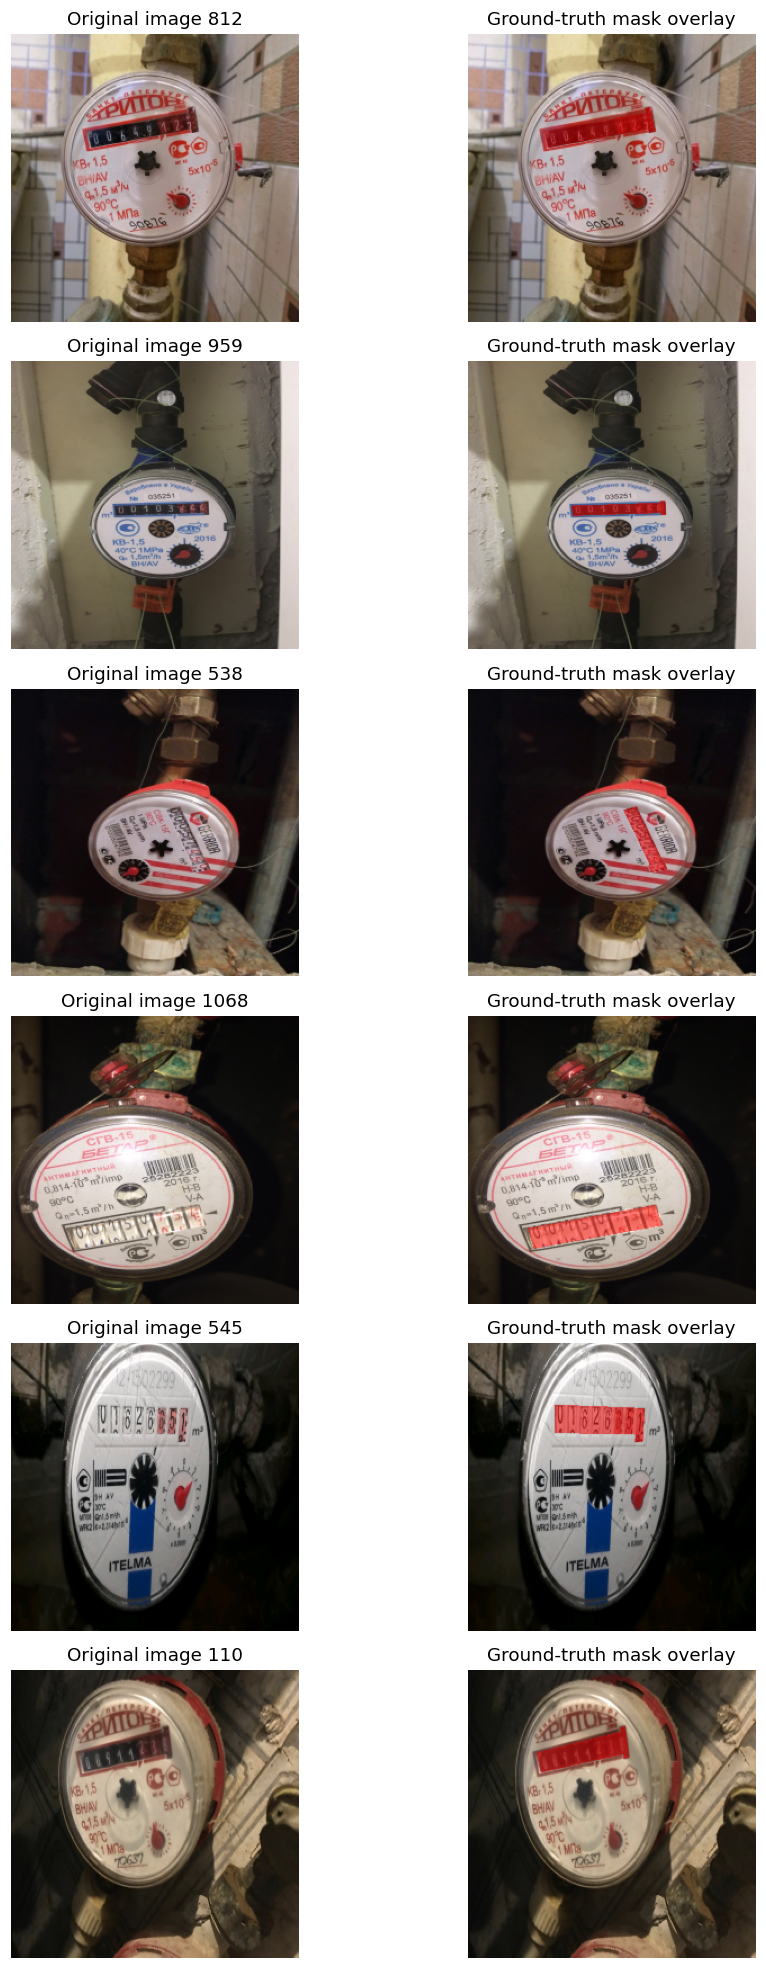

In [ ]:

# Checks whether each ground-truth mask matches its photograph

import matplotlib.pyplot as plt
import numpy as np

n_show = min(6, len(IMG256))
indices = np.random.default_rng(42).choice(
    len(IMG256), size=n_show, replace=False
)

fig, axes = plt.subplots(n_show, 2, figsize=(10, 3 * n_show))

for row, i in enumerate(indices):
    image = IMG256[i].copy()
    mask = MASK256[i].astype(bool)

    # Original photograph
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original image {i}")
    axes[row, 0].axis("off")

    # Mask drawn over the photograph
    overlay = image.copy()
    overlay[mask] = (
        0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title("Ground-truth mask overlay")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


## Exploring the Dataset

After cleaning, we examine the photographs to understand what the system will need to handle.

The charts and examples show differences in photograph size, display position, angle, lighting and image quality. These differences matter because the system should be able to find and read displays in photographs taken under different conditions.

The examples also help us check that the display markings and prepared crops match the actual photographs.


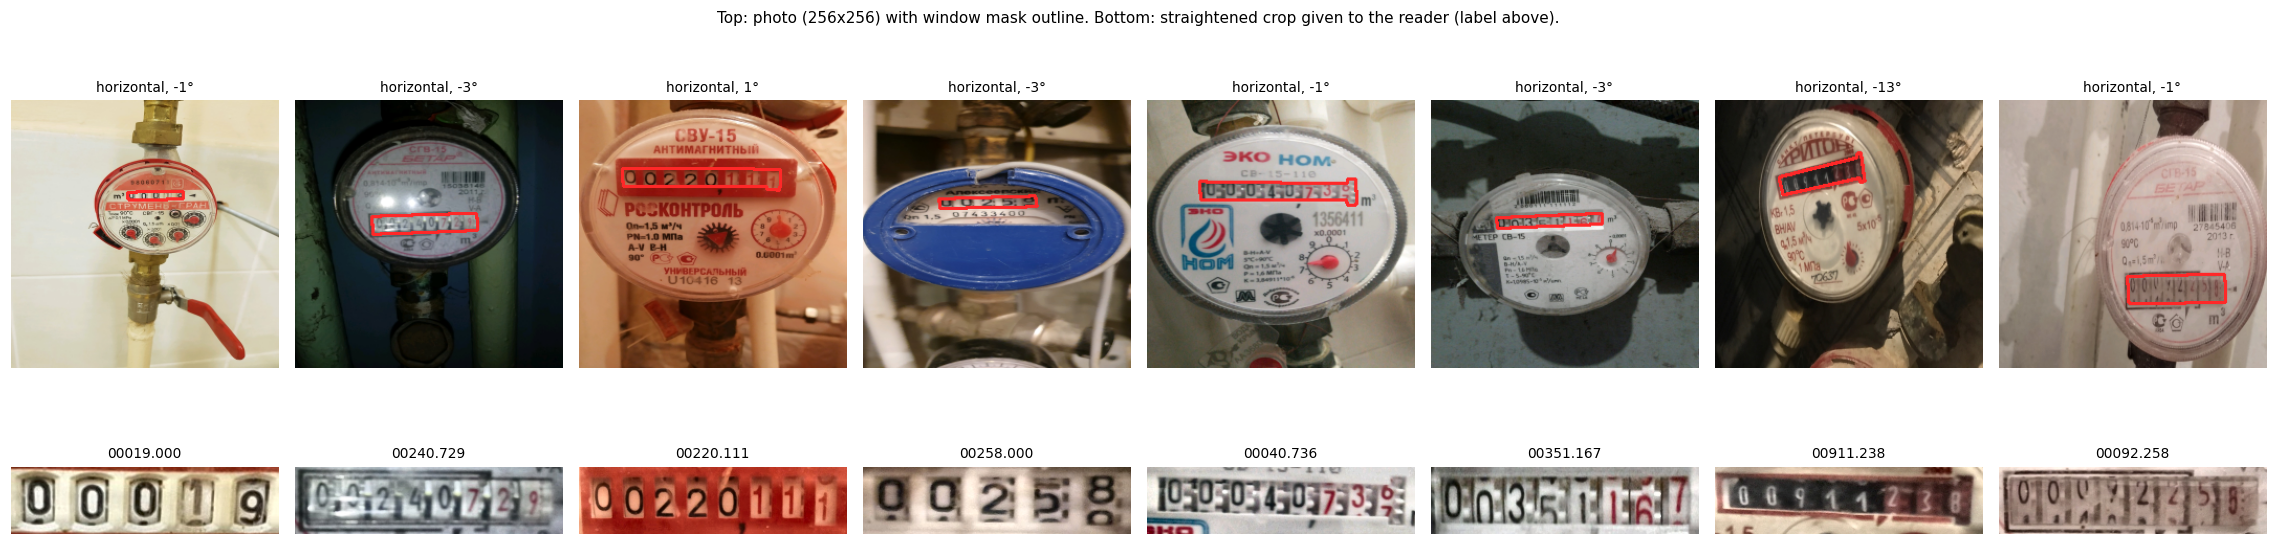

In [ ]:
rng = np.random.default_rng(SEED)
pick = rng.choice(len(ds), size=min(8, len(ds)), replace=False)
fig, axes = plt.subplots(2, len(pick), figsize=(2.6 * len(pick), 6.2))
axes = np.atleast_2d(axes)
for j, i in enumerate(pick):
    im = IMG256[i].copy()
    cnts = cv2.findContours(MASK256[i], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    cv2.drawContours(im, cnts, -1, (255, 40, 40), 2)
    axes[0, j].imshow(im); axes[0, j].set_title(f"{ds.orient[i]}, {ds.angle[i]:.0f}°", fontsize=9); axes[0, j].axis('off')
    axes[1, j].imshow(CROPS_RAW[i]); axes[1, j].set_title(fmt_reading(DIG[i]), fontsize=9); axes[1, j].axis('off')
plt.suptitle('Top: photo (256x256) with window mask outline. Bottom: straightened crop given to the reader (label above).', y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

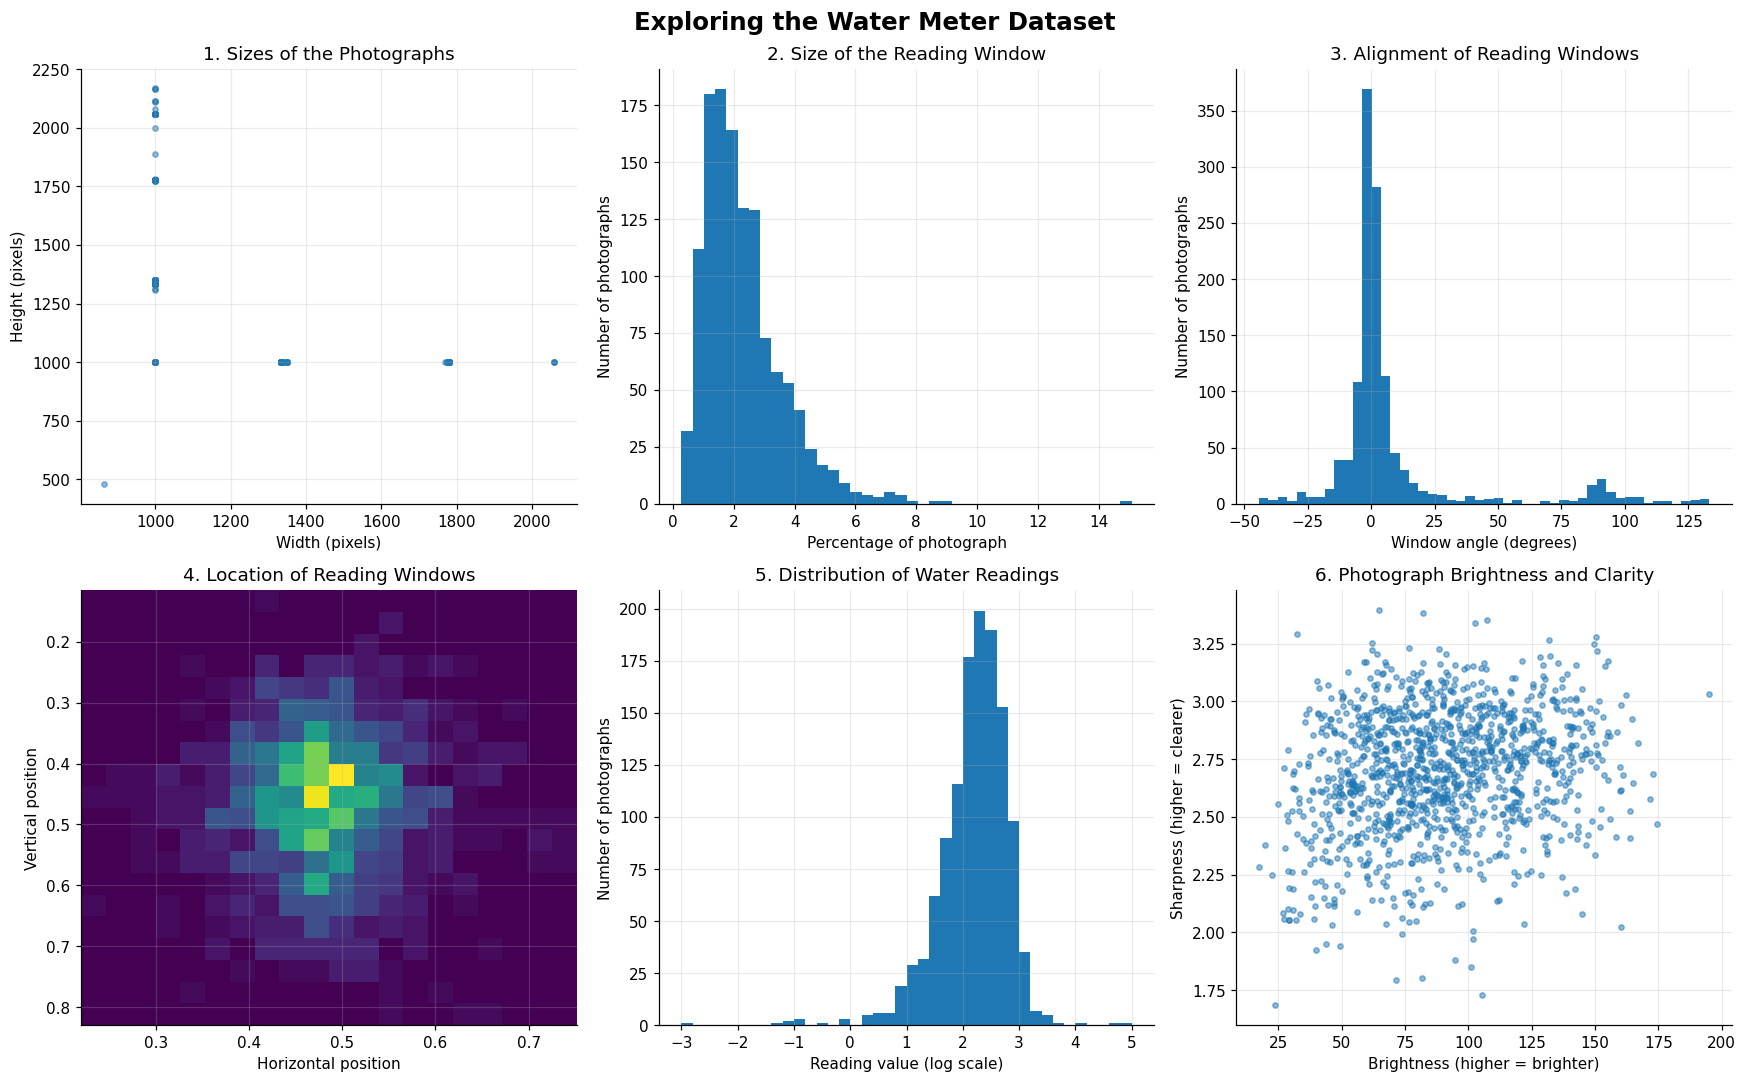

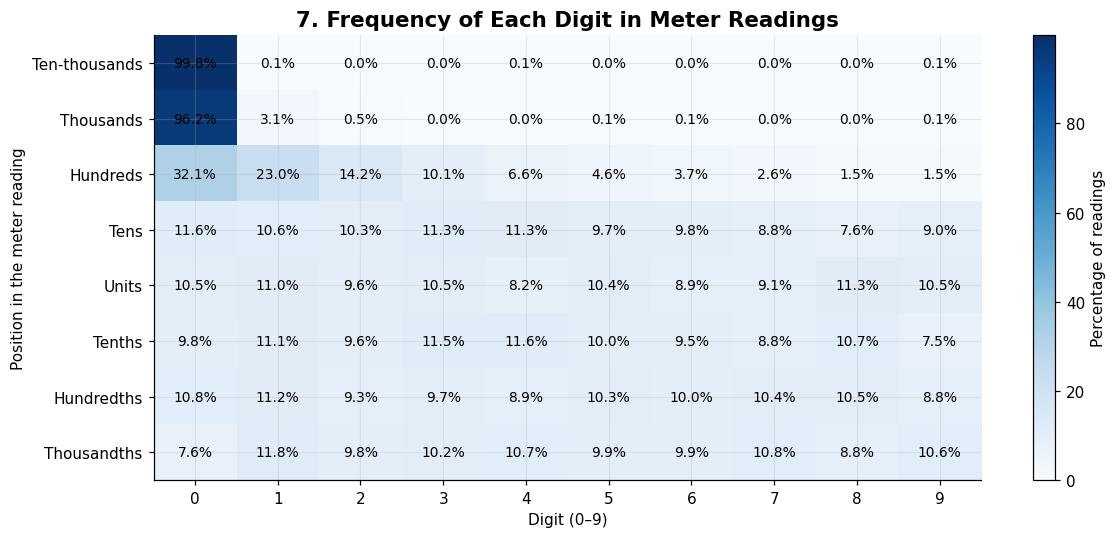

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# 1. EXPLORING THE WATER METER PHOTOGRAPHS

fig, ax = plt.subplots(2, 3, figsize=(16, 10))

# Graph 1: Photograph sizes
ax[0, 0].scatter(ds.W, ds.H, s=12, alpha=0.5)
ax[0, 0].set_title("1. Sizes of the Photographs")
ax[0, 0].set_xlabel("Width (pixels)")
ax[0, 0].set_ylabel("Height (pixels)")

# Graph 2: Reading window sizes
ax[0, 1].hist(ds.area_frac * 100, bins=40)
ax[0, 1].set_title("2. Size of the Reading Window")
ax[0, 1].set_xlabel("Percentage of photograph")
ax[0, 1].set_ylabel("Number of photographs")

# Graph 3: Reading window alignment
ax[0, 2].hist(ds.angle, bins=48)
ax[0, 2].set_title("3. Alignment of Reading Windows")
ax[0, 2].set_xlabel("Window angle (degrees)")
ax[0, 2].set_ylabel("Number of photographs")

# Graph 4: Reading window location
h = ax[1, 0].hist2d(
    ds.cx, ds.cy,
    bins=20
)
ax[1, 0].invert_yaxis()
ax[1, 0].set_title("4. Location of Reading Windows")
ax[1, 0].set_xlabel("Horizontal position")
ax[1, 0].set_ylabel("Vertical position")

# Graph 5: Water meter readings
ax[1, 1].hist(np.log10(ds.value + 1e-3), bins=40)
ax[1, 1].set_title("5. Distribution of Water Readings")
ax[1, 1].set_xlabel("Reading value (log scale)")
ax[1, 1].set_ylabel("Number of photographs")

# Graph 6: Photograph brightness and clarity
ax[1, 2].scatter(
    ds.brightness,
    np.log10(ds.sharpness + 1),
    s=12,
    alpha=0.5
)
ax[1, 2].set_title("6. Photograph Brightness and Clarity")
ax[1, 2].set_xlabel("Brightness (higher = brighter)")
ax[1, 2].set_ylabel("Sharpness (higher = clearer)")

fig.suptitle(
    "Exploring the Water Meter Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 2. UNDERSTANDING THE DIGITS IN READINGS

Rm = ds.reader_ok.values

freq = np.stack([
    np.bincount(DIG[Rm][:, p], minlength=10) / Rm.sum()
    for p in range(N_DIGITS)
])

fig, ax = plt.subplots(figsize=(11, 5))

im = ax.imshow(
    freq * 100,
    cmap="Blues",
    aspect="auto"
)

# Displays digit values along the horizontal axis
ax.set_xticks(range(10))
ax.set_xticklabels(range(10))

# Displays reading positions along the vertical axis
ax.set_yticks(range(N_DIGITS))
ax.set_yticklabels([
    "Ten-thousands",
    "Thousands",
    "Hundreds",
    "Tens",
    "Units",
    "Tenths",
    "Hundredths",
    "Thousandths"
])

# Adds percentages inside each heatmap cell
for i in range(N_DIGITS):
    for j in range(10):
        ax.text(
            j, i,
            f"{freq[i, j] * 100:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

ax.set_title(
    "7. Frequency of Each Digit in Meter Readings",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Digit (0–9)")
ax.set_ylabel("Position in the meter reading")

fig.colorbar(
    im,
    ax=ax,
    label="Percentage of readings"
)

plt.tight_layout()
plt.show()


In [ ]:
OBS = []

# Observation 1: Image sizes
modal = ds.groupby(['W', 'H']).size().sort_values(ascending=False)
(mw, mh), mc = modal.index[0], modal.iloc[0]

OBS.append(
    f"""
OBSERVATION 1: IMAGE SIZES

Most common image size: {mw} x {mh} pixels
Photos with this size: {mc / len(ds):.1%}
Image widths range from: {ds.W.min()} to {ds.W.max()} pixels
Image heights range from: {ds.H.min()} to {ds.H.max()} pixels

DECISION:
Images have different sizes, so we will resize them to {SEG_SIZE} x {SEG_SIZE}
before sending them to the U-Net model. We will also resize the reading window
to a fixed {CROP_H} x {CROP_W} size before reading the digits.
"""
)

# Observation 2: Reading window size
med = ds.area_frac.median()
q1 = ds.area_frac.quantile(.25)
q3 = ds.area_frac.quantile(.75)

OBS.append(
    f"""
OBSERVATION 2: SIZE OF THE READING WINDOW

The reading window covers a median of {med:.2%} of each image.
Most windows cover between {q1:.2%} and {q3:.2%} of the image.
The largest window covers {ds.area_frac.max():.2%}.

DECISION:
The reading window is small, so detecting it accurately is important.
We will use Dice and IoU scores to measure how well the model finds it.
After detecting the window, we will crop it before reading the digits.
"""
)

# Observation 3: Reading window direction
pct = ds.orient.value_counts(normalize=True)
hz = ds.loc[ds.orient == 'horizontal', 'angle'].abs()

OBS.append(
    f"""
OBSERVATION 3: READING WINDOW DIRECTION

Horizontal windows: {pct.get('horizontal', 0):.1%}
Diagonal windows: {pct.get('diagonal', 0):.1%}
Vertical windows: {pct.get('vertical', 0):.1%}

The median tilt of horizontal windows is {hz.median():.1f} degrees.

DECISION:
Some reading windows are tilted or turned.
We will straighten them before reading the digits.
We will also train the model to recognise upright and upside-down readings.
"""
)

# Observation 4: Digit distribution
ent = [
    stats.entropy(np.bincount(DIG[Rm][:, p], minlength=10), base=2)
    for p in range(N_DIGITS)
]

modal_share = freq.max(1)
strs = pd.Series([fmt_reading(d) for d in DIG[Rm]])
major_exact = strs.value_counts(normalize=True).iloc[0]

OBS.append(
    f"""
OBSERVATION 4: DISTRIBUTION OF DIGITS

The most common digit in the first position is '{freq[0].argmax()}'.
It appears {modal_share[0]:.0%} of the time.

The most common digit in the last position appears {modal_share[-1]:.0%} of the time.

A model that always guesses the most common digit would achieve:
- Average digit accuracy: {modal_share.mean():.1%}
- Full reading accuracy: {major_exact:.2%}

DECISION:
Checking individual digits is not enough.
We will also measure whether the model predicts the entire water meter
reading correctly and whether it gets the first five digits correct.
"""
)

# Observation 5: Water meter readings
v = ds.value.values

OBS.append(
    f"""
OBSERVATION 5: WATER METER READINGS

Lowest reading: {v.min():.3f} m³
Highest reading: {v.max():.3f} m³
Median reading: {np.median(v):.1f} m³

Photos with a zero decimal part: {ds.int_only.mean():.1%}
Number of these photos: {int(ds.int_only.sum())}

DECISION:
Some meters do not clearly display the decimal digits.
These readings will be excluded from digit reading during data preparation.
"""
)

# Observation 6: Photo quality
lowq = (ds.sharpness < ds.sharpness.quantile(.10)).mean()

OBS.append(
    f"""
OBSERVATION 6: PHOTO QUALITY

Image brightness ranges from:
{ds.brightness.quantile(.05):.0f} to {ds.brightness.quantile(.95):.0f}

Image contrast ranges from:
{ds.contrast.quantile(.05):.0f} to {ds.contrast.quantile(.95):.0f}

Some images are much less clear than others.
The lowest-quality 10% of photos have particularly low sharpness.

DECISION:
We will improve image clarity before reading the digits.
We will also train the model using images with different brightness,
contrast, blur and noise levels.
"""
)

# Observation 7: Reading window markings
pad_aspect = ds.aspect * (1 + 2 * 0.04) / (1 + 2 * 0.18)
stretch = (CROP_W / CROP_H) / pad_aspect

OBS.append(
    f"""
OBSERVATION 7: READING WINDOW MARKINGS

Median overlap between the CSV markings and mask files:
{ds.poly_mask_iou.median():.3f}

Lowest 5% overlap:
{ds.poly_mask_iou.quantile(.05):.3f}

Median reading-window shape ratio:
{pad_aspect.median():.1f}

Median stretching factor when resized:
{stretch.median():.2f}

DECISION:
The CSV markings and mask files are generally consistent.
We will use the masks to train the model to locate the reading window.
If the digits are stretched too much, we may need to adjust the crop size.
"""
)

# Display all observations clearly
print("=" * 65)
print("WATER METER DATASET: KEY FINDINGS")
print("=" * 65)

for observation in OBS:
    print(observation)
    print("-" * 65)

print("Dataset analysis completed.")

WATER METER DATASET: KEY FINDINGS

OBSERVATION 1: IMAGE SIZES

Most common image size: 1000 x 1333 pixels
Photos with this size: 73.4%
Image widths range from: 864 to 2058 pixels
Image heights range from: 480 to 2168 pixels

DECISION:
Images have different sizes, so we will resize them to 256 x 256
before sending them to the U-Net model. We will also resize the reading window
to a fixed 64 x 256 size before reading the digits.

-----------------------------------------------------------------

OBSERVATION 2: SIZE OF THE READING WINDOW

The reading window covers a median of 2.04% of each image.
Most windows cover between 1.36% and 2.88% of the image.
The largest window covers 15.09%.

DECISION:
The reading window is small, so detecting it accurately is important.
We will use Dice and IoU scores to measure how well the model finds it.
After detecting the window, we will crop it before reading the digits.

-----------------------------------------------------------------

OBSERVATION 3: R

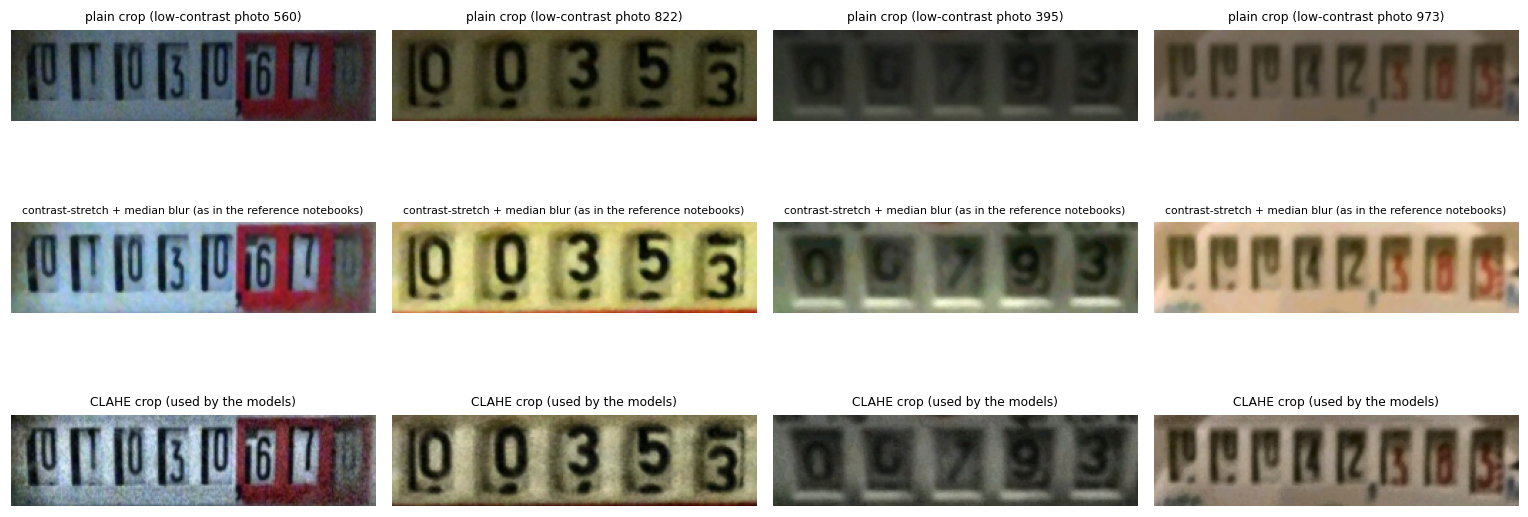

In [ ]:
low = np.argsort(ds.contrast.values)[:4]
fig, ax = plt.subplots(3, 4, figsize=(14, 6))
for j, i in enumerate(low):
    im_, m_, _ = read_aligned(ds.img_path[i], ds.mask_path[i])
    rgb_ = cv2.cvtColor(im_, cv2.COLOR_BGR2RGB); geo_ = window_geometry((m_ > 127).astype(np.uint8))
    plain = warp_window(rgb_, geo_, clahe=False)
    ax[0, j].imshow(plain); ax[0, j].set_title(f'plain crop (low-contrast photo {i})', fontsize=8); ax[0, j].axis('off')
    ax[1, j].imshow(cv2.medianBlur(cv2.normalize(plain, None, 0, 255, cv2.NORM_MINMAX), 3)); ax[1, j].set_title('contrast-stretch + median blur (as in the reference notebooks)', fontsize=7); ax[1, j].axis('off')
    ax[2, j].imshow(CROPS_RAW[i]); ax[2, j].set_title('CLAHE crop (used by the models)', fontsize=8); ax[2, j].axis('off')
plt.tight_layout(); plt.show()

# Part 3 · Preparing and Training the First Models

This part prepares the photographs and trains the models that make up the reading process.

The system has three main jobs:

1. Find the display area.
2. Check and correct its direction.
3. Read the digits.

The photographs are divided into development and test groups. The test photographs are kept separate so they can provide a final check using images the models have not seen during training.

Similar photographs are kept together when the data is divided. This reduces the chance of the same or nearly identical image appearing in both training and testing.

The first digit reader in this section is a CNN. It provides a starting point for comparison with Random Forest and the other models in Part 4.


In [ ]:
N_FOLDS = 3 if FAST_DEV else 5

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
dev_idx, test_idx = next(gss.split(ds, groups=ds.group))
ds['split'] = 'dev'; ds.loc[test_idx, 'split'] = 'test'
R_dev  = np.array([i for i in dev_idx  if ds.reader_ok[i]])
R_test = np.array([i for i in test_idx if ds.reader_ok[i]])
print(f'segmentation set: dev {len(dev_idx)} | test {len(test_idx)}      reading set: dev {len(R_dev)} | test {len(R_test)}')

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
a, b = next(gss2.split(dev_idx, groups=ds.group.values[dev_idx]))
SEG_TR, SEG_VA = dev_idx[a], dev_idx[b]

perm = np.random.default_rng(SEED).permutation(len(R_dev)); R_dev_sh = R_dev[perm]
FOLDS = [(R_dev_sh[tr], R_dev_sh[te]) for tr, te in GroupKFold(n_splits=N_FOLDS).split(R_dev_sh, groups=ds.group.values[R_dev_sh])]
print('fold sizes (train/test):', [(len(t), len(e)) for t, e in FOLDS])

segmentation set: dev 1057 | test 187      reading set: dev 1021 | test 187
fold sizes (train/test): [(816, 205), (817, 204), (817, 204), (817, 204), (817, 204)]


### 3.3 Preparing Different Training Examples

The training photographs are given small changes, such as slight rotations, shifts, brightness changes and blur. This helps the models cope with normal differences in how meter photographs are taken.

The display markings receive the same changes as their photographs so they continue to point to the correct area.

Changes to digit images are kept small, and the images are not flipped because that could change how a digit looks.

These changes are used for training only. The original photographs and the held-back test images are not altered.


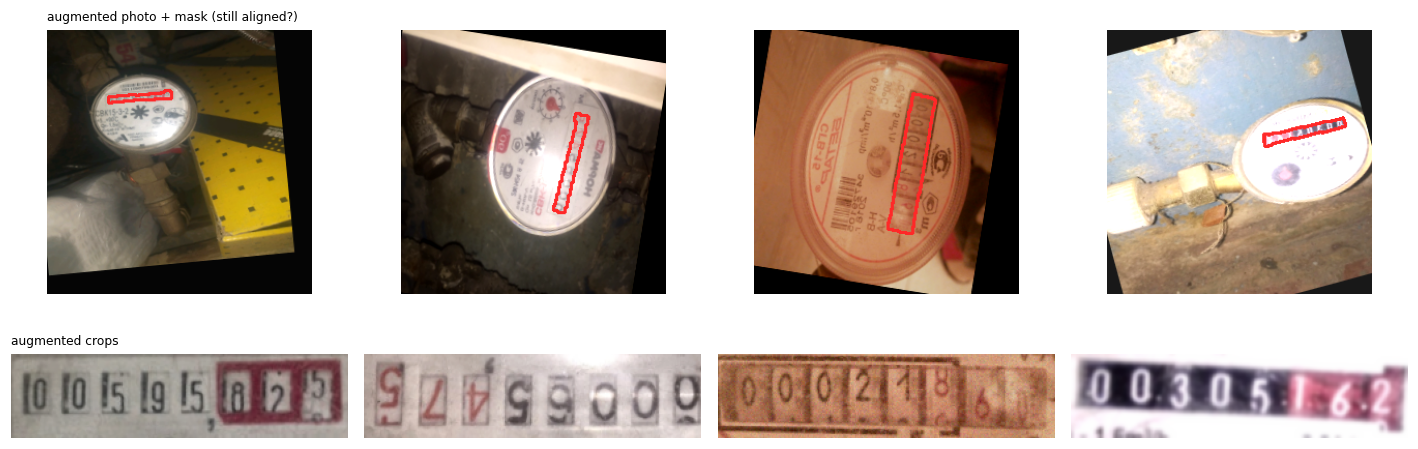

In [ ]:
def aug_seg(xb, yb, rng):
    xs, ys = [], []
    for x, y in zip(xb, yb):
        h, w = x.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-20, 20), rng.uniform(.85, 1.15))
        M[:, 2] += rng.uniform(-.08, .08, 2) * [w, h]
        x2 = cv2.warpAffine(x, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
        y2 = cv2.warpAffine(y[..., 0].astype(np.float32), M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
        if rng.random() < .5: x2, y2 = x2[:, ::-1], y2[:, ::-1]
        x2 = np.clip(x2.astype(np.float32) * rng.uniform(.7, 1.3) + rng.uniform(-25, 25), 0, 255).astype(np.uint8)
        xs.append(np.ascontiguousarray(x2)); ys.append((np.ascontiguousarray(y2) > .5).astype(np.float32)[..., None])
    return np.stack(xs), np.stack(ys)

def aug_crop(xb, rng):
    out = []
    for x in xb:
        h, w = x.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-3, 3), rng.uniform(.93, 1.07))
        M[:, 2] += [rng.uniform(-.02, .02) * w, rng.uniform(-.06, .06) * h]
        x2 = cv2.warpAffine(x, M, (w, h), borderMode=cv2.BORDER_REPLICATE).astype(np.float32)
        x2 = x2 * rng.uniform(.75, 1.25) + rng.uniform(-20, 20)
        if rng.random() < .3: x2 = cv2.GaussianBlur(np.clip(x2, 0, 255), (0, 0), rng.uniform(.5, 1.5))
        if rng.random() < .3: x2 = x2 + rng.normal(0, rng.uniform(2, 8), x2.shape)
        out.append(np.clip(x2, 0, 255).astype(np.uint8))
    return np.stack(out)

# visual sanity check of the augmentations
rg = np.random.default_rng(0)
xa, ya = aug_seg(IMG256[SEG_TR[:4]], MASK256[SEG_TR[:4]][..., None].astype(np.float32), rg)
ca = aug_crop(CROPS_RAW[SEG_TR[:4]], rg)
fig, ax = plt.subplots(2, 4, figsize=(13, 5))
for j in range(4):
    o = xa[j].copy(); cv2.drawContours(o, cv2.findContours(ya[j, ..., 0].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2], -1, (255, 40, 40), 2)
    ax[0, j].imshow(o); ax[0, j].axis('off'); ax[1, j].imshow(ca[j]); ax[1, j].axis('off')
ax[0, 0].set_title('augmented photo + mask (still aligned?)', fontsize=8, loc='left'); ax[1, 0].set_title('augmented crops', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

### 3.4 Training the Image Models

This section defines how the image models are trained.

The models learn from the prepared photographs and are checked against separate validation examples while training. Training can stop when a model no longer improves.

These steps help reduce the chance of a model simply memorising the training photographs. The same general checks are used when comparing the image models.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers as L, regularizers
try: tf.keras.utils.set_random_seed(SEED)
except Exception: pass
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

def _scalar(v):
    if isinstance(v, (list, tuple, np.ndarray)): v = np.ravel(v)[0]
    return float(v)

def _f32(x): return x.astype(np.float32) / 255.0

def fit_loop(model, Xtr, Ytr, Xva, Yva, epochs, batch, patience, lr, aug=None, seed=SEED):
    rng = np.random.default_rng(seed)
    best, best_w, wait = np.inf, None, 0
    hist = {'loss': [], 'val_loss': []}
    for ep in range(epochs):
        order = rng.permutation(len(Xtr)); tl = []
        for s in range(0, len(order), batch):
            b = order[s:s + batch]
            if len(b) < 2: continue
            xb, yb = Xtr[b], Ytr[b]
            if aug is not None: xb, yb = aug(xb, yb, rng)
            tl.append(_scalar(model.train_on_batch(_f32(xb), yb)))
        vl, vn = 0.0, 0
        for s in range(0, len(Xva), 64):
            xv, yv = Xva[s:s + 64], Yva[s:s + 64]
            vl += _scalar(model.test_on_batch(_f32(xv), yv)) * len(xv); vn += len(xv)
        val = vl / vn
        hist['loss'].append(float(np.mean(tl))); hist['val_loss'].append(float(val))
        if val < best - 1e-4:
            best, best_w, wait = val, model.get_weights(), 0
        else:
            wait += 1
            if wait == max(2, patience // 2):
                lr *= 0.5
                try: model.optimizer.learning_rate.assign(lr)
                except Exception: pass
            if wait >= patience: break
    if best_w is not None: model.set_weights(best_w)
    return hist

def build_unet(input_shape=(SEG_SIZE, SEG_SIZE, 3), base=16, l2=1e-5, dropout=0.1):
    reg = regularizers.l2(l2)
    def block(x, f):
        for _ in range(2):
            x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
            x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
        return x
    inp = L.Input(input_shape); x = inp; skips = []
    for i in range(4):
        x = block(x, base * 2 ** i); skips.append(x); x = L.MaxPooling2D(2)(x)
    x = L.Dropout(dropout)(block(x, base * 2 ** 4))
    for i in reversed(range(4)):
        x = L.UpSampling2D(2, interpolation='bilinear')(x)
        x = L.Concatenate()([x, skips[i]])
        x = block(x, base * 2 ** i)
    return tf.keras.Model(inp, L.Conv2D(1, 1, activation='sigmoid')(x), name='unet')

def bce_dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred), axis=[1, 2])
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    den = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return bce + (1.0 - (2.0 * inter + 1.0) / (den + 1.0))

def train_unet(Xtr, Ytr, Xva, Yva, loss='bce_dice', augment=True, epochs=None, seed=SEED, verbose=1):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_unet()
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=bce_dice_loss if loss == 'bce_dice' else 'binary_crossentropy')
    hist = fit_loop(m, Xtr, Ytr, Xva, Yva, epochs or EPOCHS['seg'], BATCH['seg'], patience=8, lr=1e-3, aug=aug_seg if augment else None, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=16, verbose=0)[..., 0]
    predict.model = m
    return predict, hist

def build_reader(variant='base'):
    reg = None if variant == 'noreg' else regularizers.l2(1e-4)
    drop = (0.0, 0.0) if variant == 'noreg' else (0.3, 0.4)
    inp = L.Input((CROP_H, CROP_W, 3))
    if variant == 'mobilenet':
        try:
            backbone = tf.keras.applications.MobileNetV2(input_shape=(CROP_H, CROP_W, 3), include_top=False, weights='imagenet')
        except Exception as e:
            print('   (ImageNet weights unavailable -> MobileNetV2 trained from scratch):', str(e)[:80])
            backbone = tf.keras.applications.MobileNetV2(input_shape=(CROP_H, CROP_W, 3), include_top=False, weights=None)
        x = backbone(L.Rescaling(2.0, offset=-1.0)(inp))
    else:
        x = inp
        for f in (32, 64, 128, 192):
            for _ in range(2):
                x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
                x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
            x = L.MaxPooling2D(2)(x)
    x = L.Dropout(drop[0])(L.Flatten()(x))
    x = L.Dropout(drop[1])(L.Dense(256, activation='relu', kernel_regularizer=reg)(x))
    x = L.Softmax(axis=-1)(L.Reshape((N_DIGITS, 10))(L.Dense(N_DIGITS * 10)(x)))
    return tf.keras.Model(inp, x, name=f'reader_{variant}')

def train_reader(Xtr, Ytr, Xva, Yva, variant='base', epochs=None, seed=SEED, verbose=0):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_reader(variant); lr = 3e-4 if variant == 'mobilenet' else 1e-3
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy')
    aug = None if variant == 'noreg' else (lambda xb, yb, rng: (aug_crop(xb, rng), yb))
    hist = fit_loop(m, Xtr, Ytr.astype(np.int32), Xva, Yva.astype(np.int32), epochs or EPOCHS['read'], BATCH['read'], patience=8, lr=lr, aug=aug, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=64, verbose=0)
    predict.model = m
    return predict, hist

def build_orient():
    reg = regularizers.l2(1e-4); inp = L.Input((CROP_H, CROP_W, 3)); x = inp
    for f in (16, 32, 64):
        x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
        x = L.BatchNormalization()(x); x = L.Activation('relu')(x); x = L.MaxPooling2D(2)(x)
    x = L.Dropout(0.3)(L.Flatten()(x)); x = L.Dropout(0.3)(L.Dense(64, activation='relu', kernel_regularizer=reg)(x))
    return tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x), name='orient')

def train_orientation(Xtr, ytr, Xva, yva, epochs=None, seed=SEED):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_orient(); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    aug = lambda xb, yb, rng: (aug_crop(xb, rng), yb)
    hist = fit_loop(m, Xtr, ytr.astype(np.float32)[:, None], Xva, yva.astype(np.float32)[:, None], epochs or EPOCHS['orient'], BATCH['orient'], patience=6, lr=1e-3, aug=aug, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=64, verbose=0)[:, 0]
    predict.model = m
    return predict, hist

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 3.5 How Model Performance Is Measured

Different measures are used because the system has more than one task.

**Finding the display**
- **IoU and Dice:** Show how closely the area found by the model matches the marked display area. Higher scores are better.
- **Success rate:** Shows how often the model finds the display area with an acceptable level of overlap.

**Reading the digits**
- **Individual-digit accuracy:** The percentage of single digits recognised correctly.
- **Whole-number accuracy:** The percentage of readings where all digits before the decimal point are correct.
- **Complete-reading accuracy:** The percentage of readings where every digit is correct.
- **Mean Absolute Error (MAE):** The average difference between the predicted and correct readings, measured in cubic metres. Lower is better.
- **Within 1 m³:** The percentage of predictions that are within one cubic metre of the correct reading.

Complete-reading accuracy is especially important because one incorrect digit can make the final meter reading wrong.


In [ ]:
def seg_scores(prob, gt, thr=0.5):
    pr = prob > thr; g = gt.astype(bool)
    inter = (pr & g).sum((1, 2)); union = (pr | g).sum((1, 2))
    return inter / np.maximum(union, 1), 2 * inter / np.maximum(pr.sum((1, 2)) + g.sum((1, 2)), 1)

def seg_summary(prob, gt, thr):
    iou, dice = seg_scores(prob, gt, thr)
    return dict(IoU=iou.mean(), Dice=dice.mean(), success_IoU50=(iou >= .5).mean(), success_IoU75=(iou >= .75).mean())

def digit_metrics(Y, P):
    eq = (P == Y); err = np.abs(digits_to_value(P) - digits_to_value(Y))
    return dict(exact=eq.all(1).mean(), m3_exact=eq[:, :5].all(1).mean(), digit_acc=eq.mean(),
                mae=float(np.nanmean(err)) if np.isfinite(err).any() else np.nan, within_1m3=float(np.mean(np.nan_to_num(err, nan=1e9) < 1)), n=len(Y))

### 3.6 Checking and Correcting the Display Direction

After the display has been found and cropped, the system checks whether it is upright or upside down.

**Why this comes before the digit readers:** a small number of photographs show the meter upside down, so their crops are upside down too. If the readers are trained on those crops, they learn from images that do not match their labels.

**How it works**
1. **Finding upside-down crops automatically.** On these meters the three decimal wheels are red and sit at the right-hand end. If the left side of a crop is clearly redder than the right side, the crop is upside down. This is a rule of thumb: it works on meters with red decimal wheels and cannot judge meters without them.
2. **Training the orientation CNN.** The corrected crops are used as "upright" examples; the same crops rotated by 180° are the "upside-down" examples. The CNN learns the difference from the digits themselves, so it also works on meters without red wheels.
3. **Correcting every crop.** The CNN's decision is used to produce `CROPS_UP`, which all digit readers use from here on.

Crops flagged as upside down by the red-wheel rule: 37 of 1244 (3.0%)


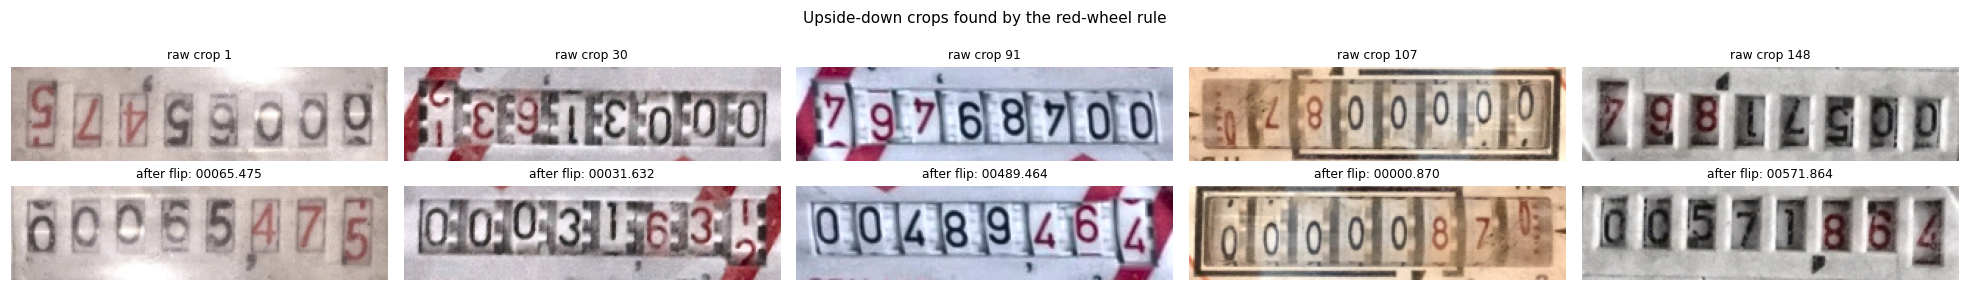

Orientation CNN on held-out test crops (upright vs rotated copies): 94.9%
Orientation decision used: CNN
Crops rotated by 180 degrees: 70 | agreement with the red-wheel rule: 97.2%
CROPS_UP ready: (1244, 64, 256, 3)


In [ ]:
def decimal_wheel_redness(crop):
    """Mean redness over the three left-most and three right-most digit slots (crop is RGB)."""
    c = crop.astype(np.float32)
    red = np.clip(c[..., 0] - (c[..., 1] + c[..., 2]) / 2, 0, None)
    cw = crop.shape[1] / N_DIGITS
    return float(red[:, :int(3 * cw)].mean()), float(red[:, int(5 * cw):].mean())

def weak_flip_rule(crops):
    r = np.array([decimal_wheel_redness(c) for c in crops])
    return r[:, 0] > r[:, 1] * 1.5 + 3          # left redder than right -> upside down

# Step 1: automatic upside-down detection from the red decimal wheels
WEAK_FLIP = weak_flip_rule(CROPS_RAW)
CROPS_WEAK_UP = np.where(WEAK_FLIP[:, None, None, None], CROPS_RAW[:, ::-1, ::-1], CROPS_RAW)
print(f'Crops flagged as upside down by the red-wheel rule: {int(WEAK_FLIP.sum())} of {len(WEAK_FLIP)} ({WEAK_FLIP.mean():.1%})')

show = np.where(WEAK_FLIP)[0][:5]
if len(show):
    fig, ax = plt.subplots(2, len(show), figsize=(3.6 * len(show), 2.8), squeeze=False)
    for j, i in enumerate(show):
        ax[0, j].imshow(CROPS_RAW[i]); ax[0, j].set_title(f'raw crop {i}', fontsize=8); ax[0, j].axis('off')
        ax[1, j].imshow(CROPS_WEAK_UP[i]); ax[1, j].set_title(f'after flip: {fmt_reading(DIG[i])}', fontsize=8); ax[1, j].axis('off')
    plt.suptitle('Upside-down crops found by the red-wheel rule', fontsize=10); plt.tight_layout(); plt.show()

# Step 2: train the orientation CNN on corrected crops (+ the same crops rotated by 180 degrees)
inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_local, va_local = next(inner.split(R_dev, groups=ds.group.values[R_dev]))
X_src = CROPS_WEAK_UP[R_dev]
X_tr_s, X_va_s = X_src[tr_local], X_src[va_local]
X_or_tr = np.concatenate([X_tr_s, X_tr_s[:, ::-1, ::-1]]); y_or_tr = np.r_[np.zeros(len(X_tr_s)), np.ones(len(X_tr_s))]
X_or_va = np.concatenate([X_va_s, X_va_s[:, ::-1, ::-1]]); y_or_va = np.r_[np.zeros(len(X_va_s)), np.ones(len(X_va_s))]
orient_predict, h_orient = train_orientation(X_or_tr, y_or_tr, X_or_va, y_or_va)

# Step 3: check on held-out test photographs
Xt = CROPS_WEAK_UP[R_test]
p_up, p_dn = orient_predict(Xt), orient_predict(Xt[:, ::-1, ::-1])
ORIENT_TEST_ACC = 0.5 * float((p_up <= .5).mean() + (p_dn > .5).mean())
print(f'Orientation CNN on held-out test crops (upright vs rotated copies): {ORIENT_TEST_ACC:.1%}')

# Step 4: correct every crop
ORIENT_USE_CNN = ORIENT_TEST_ACC >= 0.90
def needs_flip(crops):
    crops = np.asarray(crops)
    return (orient_predict(crops) > .5) if ORIENT_USE_CNN else weak_flip_rule(crops)

ORIENT_FLIP = needs_flip(CROPS_RAW)
CROPS_UP = np.where(ORIENT_FLIP[:, None, None, None], CROPS_RAW[:, ::-1, ::-1], CROPS_RAW)
CROPS_DIGIT_UP = CROPS_UP
print(f"Orientation decision used: {'CNN' if ORIENT_USE_CNN else 'red-wheel rule (CNN accuracy below 90%)'}")
print(f'Crops rotated by 180 degrees: {int(ORIENT_FLIP.sum())} | agreement with the red-wheel rule: {(ORIENT_FLIP == WEAK_FLIP).mean():.1%}')
print('CROPS_UP ready:', CROPS_UP.shape)

### 3.7 Finding the Reading Window

U-Net is trained to identify the display area in each photograph. The marked areas supplied with the dataset are used as examples.

The model is checked using validation photographs, and the best setting is chosen before the final test. The test photographs are kept separate until this final evaluation.

The results show how closely the display area found by the model matches the marked area.


U-Net trained in 414s, 20 epochs (early stopping may stop before 20)


,threshold,IoU,Dice,success_IoU50,success_IoU75
0,0.20,0.807,0.874,0.893,0.792
1,0.25,0.806,0.873,0.893,0.786
2,0.30,0.804,0.871,0.887,0.780
3,0.35,0.803,0.870,0.887,0.792
4,0.40,0.801,0.868,0.893,0.786
5,0.45,0.799,0.867,0.893,0.780
6,0.50,0.797,0.865,0.887,0.780
7,0.55,0.795,0.864,0.887,0.780
8,0.60,0.793,0.862,0.887,0.780
9,0.65,0.791,0.860,0.887,0.780


Threshold chosen on VALIDATION data: 0.2


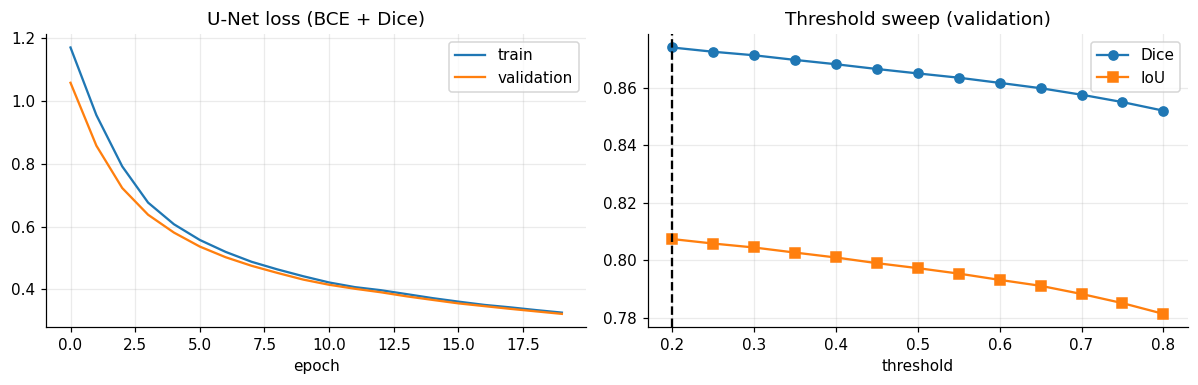

TEST segmentation (base U-Net): {'IoU': np.float64(0.817), 'Dice': np.float64(0.88), 'success_IoU50': np.float64(0.914), 'success_IoU75': np.float64(0.807)}


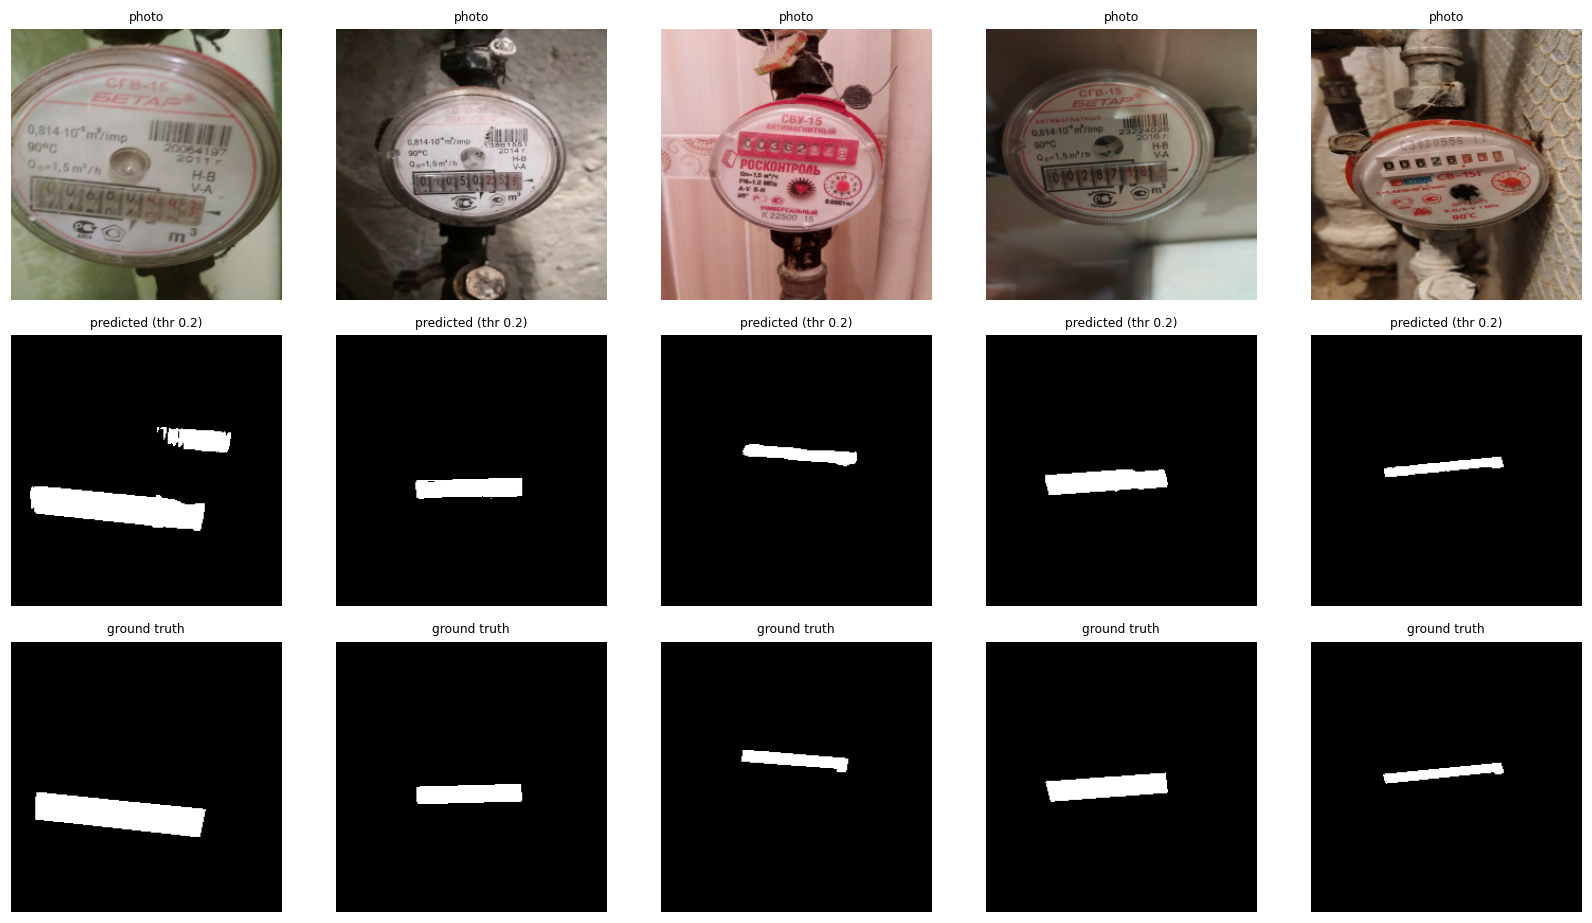

In [ ]:
if 'EPOCHS' not in globals():
    EPOCHS = {'seg': 20, 'read': 20, 'orient': 15}
if 'BATCH' not in globals():
    BATCH = {'seg': 8, 'read': 32, 'orient': 32}

Xs_tr, Ys_tr = IMG256[SEG_TR], MASK256[SEG_TR][..., None].astype(np.float32)
Xs_va, Ys_va = IMG256[SEG_VA], MASK256[SEG_VA][..., None].astype(np.float32)
t0 = time.time()
unet_predict, h_unet = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce_dice', augment=True)
print(f'U-Net trained in {time.time() - t0:.0f}s, {len(h_unet["loss"])} epochs (early stopping may stop before {EPOCHS["seg"]})')

P_va = unet_predict(Xs_va)
sweep = pd.DataFrame([dict(threshold=round(t, 2), **seg_summary(P_va, MASK256[SEG_VA], t)) for t in np.arange(.2, .81, .05)])
BEST_THR = float(sweep.loc[sweep.Dice.idxmax(), 'threshold'])
display(sweep.round(3)); print('Threshold chosen on VALIDATION data:', BEST_THR)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h_unet['loss'], label='train'); ax[0].plot(h_unet['val_loss'], label='validation'); ax[0].set_title('U-Net loss (BCE + Dice)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(sweep.threshold, sweep.Dice, 'o-', label='Dice'); ax[1].plot(sweep.threshold, sweep.IoU, 's-', label='IoU'); ax[1].axvline(BEST_THR, ls='--', c='k'); ax[1].set_title('Threshold sweep (validation)'); ax[1].set_xlabel('threshold'); ax[1].legend()
plt.tight_layout(); plt.show()

P_te = unet_predict(IMG256[test_idx])
base_seg_test = seg_summary(P_te, MASK256[test_idx], BEST_THR)
print('TEST segmentation (base U-Net):', {k: round(v, 3) for k, v in base_seg_test.items()})
sel = np.random.default_rng(1).choice(len(test_idx), size=min(5, len(test_idx)), replace=False)
fig, ax = plt.subplots(3, len(sel), figsize=(3 * len(sel), 8.5), squeeze=False)
for j, n in enumerate(sel):
    i = test_idx[n]; ax[0, j].imshow(IMG256[i]); ax[0, j].axis('off'); ax[0, j].set_title('photo', fontsize=8)
    ax[1, j].imshow(P_te[n] > BEST_THR, cmap='gray'); ax[1, j].axis('off'); ax[1, j].set_title(f'predicted (thr {BEST_THR})', fontsize=8)
    ax[2, j].imshow(MASK256[i], cmap='gray'); ax[2, j].axis('off'); ax[2, j].set_title('ground truth', fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:

# Inspects the U-Net predicted probabilities

P_val = unet_predict(Xs_va)

print("Prediction shape:", P_val.shape)
print("Minimum probability:", P_val.min())
print("Maximum probability:", P_val.max())
print("Mean probability:", P_val.mean())

print("\nProbability distribution:")

for threshold in [0.2, 0.35, 0.5, 0.65, 0.8]:
    percentage = np.mean(P_val >= threshold) * 100
    print(f"Threshold {threshold}: {percentage:.2f}% pixels predicted as foreground")


Prediction shape: (159, 256, 256)
Minimum probability: 7.776966e-12
Maximum probability: 1.0
Mean probability: 0.0207365

Probability distribution:
Threshold 0.2: 2.18% pixels predicted as foreground
Threshold 0.35: 2.12% pixels predicted as foreground
Threshold 0.5: 2.07% pixels predicted as foreground
Threshold 0.65: 2.03% pixels predicted as foreground
Threshold 0.8: 1.97% pixels predicted as foreground


In [ ]:
print("Dataset rows:", len(ds))
print("Images:", len(IMG256))
print("Masks:", len(MASK256))
print("Raw crops:", len(CROPS_RAW))

assert len(ds) == len(IMG256) == len(MASK256) == len(CROPS_RAW), \
    "Dataset arrays are not aligned!"

Dataset rows: 1244
Images: 1244
Masks: 1244
Raw crops: 1244


### 3.8 Preparing the Digit-Reading Models

The display crops are prepared in a consistent size so that the different digit-reading models can be compared fairly.

For the traditional machine-learning models, the notebook creates a set of image details that describe the edges and shapes in each digit. Random Forest and the other traditional models use these details to make their predictions.

The CNN reader is also trained as a comparison model. The results from Part 4 are used to decide which digit-reading method performed best.

The models are checked across several training and validation splits. This gives a better indication of whether their results are consistent than relying on a single split.


In [ ]:
if 'CROPS_UP' not in globals() or len(globals().get('CROPS_UP', [])) == 0:
    CROPS_UP = CROPS_RAW

def hog_features(crops):
    out = []
    for c in crops:
        g = cv2.resize(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), (128, 32), interpolation=cv2.INTER_AREA)
        out.append(hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True))
    return np.asarray(out, np.float32)

F_ALL = hog_features(CROPS_UP)
print('HOG feature matrix successfully created! Shape:', F_ALL.shape)

n_trees = 60 if FAST_DEV else 300
CLASSICAL = {
    'Majority class (dummy)': lambda: DummyClassifier(strategy='most_frequent'),
    'Logistic Regression':    lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, C=0.5)),
    'k-NN (k=5)':             lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    'Decision Tree':          lambda: DecisionTreeClassifier(max_depth=15, random_state=SEED),
    'Naive Bayes':            lambda: make_pipeline(StandardScaler(), GaussianNB()),
    'Random Forest':          lambda: RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=SEED),
    'SVM (RBF)':              lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma='scale'))
}
MODELS = {n: ('sk', f) for n, f in CLASSICAL.items()}
MODELS['CNN, no regularisation'] = ('cnn', 'noreg')
MODELS['CNN transfer (MobileNetV2)'] = ('cnn', 'mobilenet')
BASE_NAME = 'CNN base (aug + dropout + L2)'
MODELS[BASE_NAME] = ('cnn', 'base')
RESULTS = {}

def fit_predict(kind, spec, tr_ids, te_ids, seed=SEED):
    Ytr = DIG[tr_ids]
    if kind == 'sk':
        pred = np.zeros((len(te_ids), N_DIGITS), dtype=np.int64)
        for p in range(N_DIGITS):
            y = Ytr[:, p]
            if len(np.unique(y)) == 1: pred[:, p] = y[0]; continue
            clf = spec(); clf.fit(F_ALL[tr_ids], y); pred[:, p] = clf.predict(F_ALL[te_ids])
        return pred, None, None
    # Group-aware inner validation: all crops from one source photograph stay together.
    inner = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=seed)
    tr_local, va_local = next(inner.split(tr_ids, groups=ds.group.values[tr_ids]))
    tr, va = tr_ids[tr_local], tr_ids[va_local]
    predict, hist = train_reader(CROPS_UP[tr], DIG[tr], CROPS_UP[va], DIG[va], variant=spec, seed=seed)
    return predict(CROPS_UP[te_ids]).argmax(-1), hist, predict

def run_model(name, verbose=True):
    kind, spec = MODELS[name]; rows, oof, hist0 = [], np.full((len(ds), N_DIGITS), -1, dtype=np.int64), None
    for k, (tr, te) in enumerate(FOLDS):
        t0 = time.time()
        pred, h, fold_predict_fn = fit_predict(kind, spec, tr, te, seed=SEED + k)
        oof[te] = pred; hist0 = hist0 if hist0 is not None else h
        m = digit_metrics(DIG[te], pred); m.update(model=name, fold=k, secs=round(time.time() - t0, 1)); rows.append(m)
        # Fold models are not needed after their predictions are collected.
        del fold_predict_fn, pred, h
        try:
            import tensorflow as tf
            tf.keras.backend.clear_session()
        except Exception:
            pass
        gc.collect()
    pred_te, h_fin, predict_fn = fit_predict(kind, spec, R_dev, R_test)
    RESULTS[name] = dict(cv=pd.DataFrame(rows), oof=oof, test=digit_metrics(DIG[R_test], pred_te), test_pred=pred_te, hist0=hist0, predict=predict_fn)
    if verbose:
        cv = RESULTS[name]['cv']
        print(f"{name:34s} CV exact {cv.exact.mean():.3f} ± {cv.exact.std():.3f} | CV m3 {cv.m3_exact.mean():.3f} | CV digit {cv.digit_acc.mean():.3f} | TEST exact {RESULTS[name]['test']['exact']:.3f}")
    return RESULTS[name]

HOG feature matrix successfully created! Shape: (1244, 1620)


In [ ]:
print("Dataset images:", len(ds))
print("Digit labels:", len(DIG))
print("Original crops:", CROPS_RAW.shape)
print("Oriented crops:", CROPS_UP.shape)
print("Training indices:", len(R_dev))
print("Test indices:", len(R_test))

Dataset images: 1244
Digit labels: 1244
Original crops: (1244, 64, 256, 3)
Oriented crops: (1244, 64, 256, 3)
Training indices: 1021
Test indices: 187


CNN base (aug + dropout + L2)      CV exact 0.000 ± 0.000 | CV m3 0.006 | CV digit 0.350 | TEST exact 0.000
Model training completed in 512 seconds.

WATER METER DIGIT READING: MODEL RESULTS


,What we measured,Average result,Meaning
0,Complete reading correct,0.0%,Percentage of complete readings predicted corr...
1,Whole-number reading correct,0.6%,Percentage of whole-number readings predicted ...
2,Individual digit accuracy,35.0%,Percentage of individual digits predicted corr...
3,Average reading error,419.259 m³,Average difference between predicted and actua...
4,Readings within 1 m³ of the correct value,0.7%,Percentage of predictions with an error of at ...



RESULT ON UNSEEN TEST IMAGES
-----------------------------------------------------------------


,What we measured,Test result
0,Complete reading correct,0.0%
1,Whole-number reading correct,0.0%
2,Individual digit accuracy,35.2%
3,Average reading error,280.686 m³
4,Readings within 1 m³ of the correct value,0.0%



Note: Cross-validation results are averages across the training folds.
Test results show how the model performed on separate, unseen images.


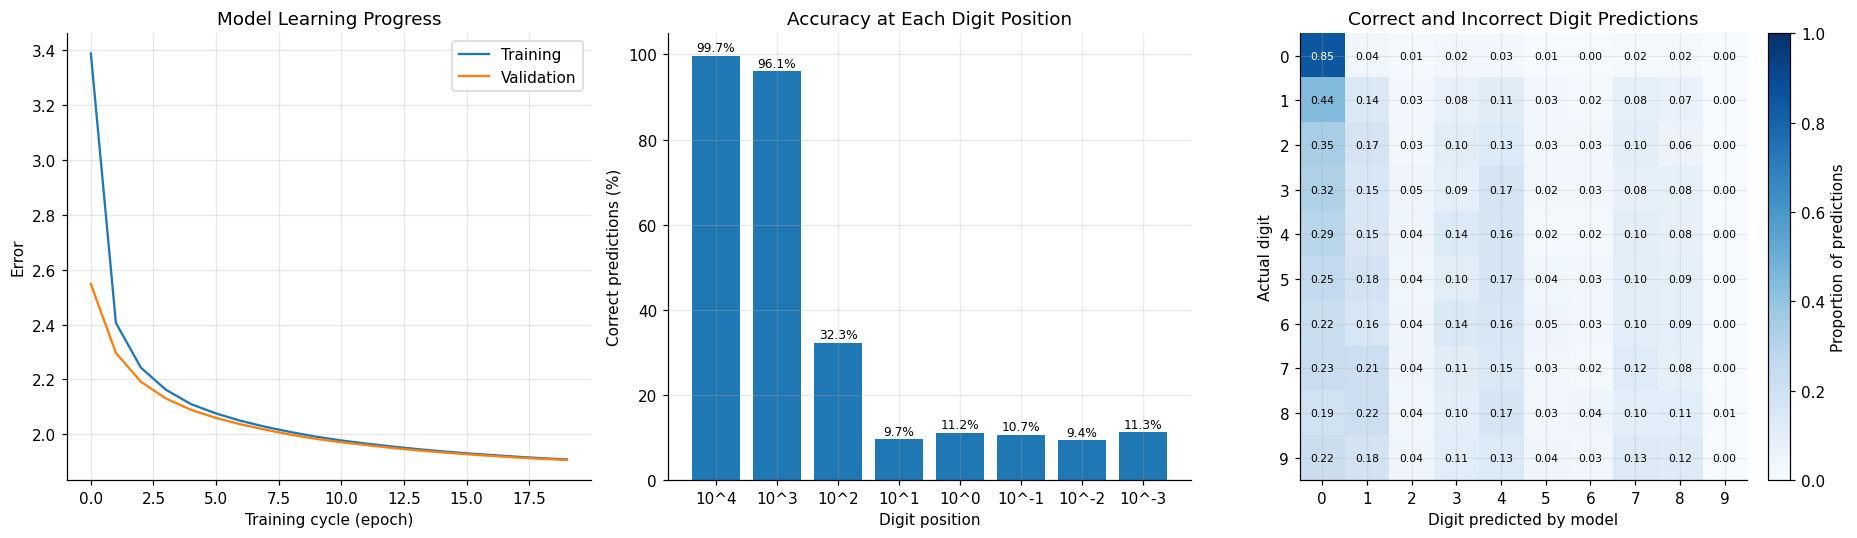

In [ ]:
t0 = time.time()
res = run_model(BASE_NAME)
print(f"Model training completed in {time.time() - t0:.0f} seconds.")

# 1. DISPLAY RESULTS IN SIMPLE ENGLISH

cvb = res['cv']

print("\n" + "=" * 65)
print("WATER METER DIGIT READING: MODEL RESULTS")
print("=" * 65)

# Creates a table
results_table = pd.DataFrame({
    'What we measured': [
        'Complete reading correct',
        'Whole-number reading correct',
        'Individual digit accuracy',
        'Average reading error',
        'Readings within 1 m³ of the correct value'
    ],
    'Average result': [
        f"{cvb['exact'].mean():.1%}",
        f"{cvb['m3_exact'].mean():.1%}",
        f"{cvb['digit_acc'].mean():.1%}",
        f"{cvb['mae'].mean():.3f} m³",
        f"{cvb['within_1m3'].mean():.1%}"
    ],
    'Meaning': [
        'Percentage of complete readings predicted correctly',
        'Percentage of whole-number readings predicted correctly',
        'Percentage of individual digits predicted correctly',
        'Average difference between predicted and actual readings',
        'Percentage of predictions with an error of at most 1 m³'
    ]
})

display(results_table)

print("\nRESULT ON UNSEEN TEST IMAGES")
print("-" * 65)

test_table = pd.DataFrame({
    'What we measured': [
        'Complete reading correct',
        'Whole-number reading correct',
        'Individual digit accuracy',
        'Average reading error',
        'Readings within 1 m³ of the correct value'
    ],
    'Test result': [
        f"{res['test']['exact']:.1%}",
        f"{res['test']['m3_exact']:.1%}",
        f"{res['test']['digit_acc']:.1%}",
        f"{res['test']['mae']:.3f} m³",
        f"{res['test']['within_1m3']:.1%}"
    ]
})

display(test_table)

print("\nNote: Cross-validation results are averages across the training folds.")
print("Test results show how the model performed on separate, unseen images.")

READER_PREDICT = res['predict']

# 2.  GRAPHS

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# Graph 1: Training progress
h0 = res['hist0']

ax[0].plot(h0['loss'], label='Training')
ax[0].plot(h0['val_loss'], label='Validation')
ax[0].set_title('Model Learning Progress')
ax[0].set_xlabel('Training cycle (epoch)')
ax[0].set_ylabel('Error')
ax[0].legend()
ax[0].grid(alpha=0.3)

# Graph 2: Accuracy for each digit position
oo = res['oof'][R_dev]
yy = DIG[R_dev]

digit_accuracy = (oo == yy).mean(0) * 100

bars = ax[1].bar(POS_LABELS, digit_accuracy)
ax[1].set_title('Accuracy at Each Digit Position')
ax[1].set_xlabel('Digit position')
ax[1].set_ylabel('Correct predictions (%)')
ax[1].set_ylim(0, 105)
ax[1].grid(axis='y', alpha=0.3)

for bar, value in zip(bars, digit_accuracy):
    ax[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.1f}%',
        ha='center',
        fontsize=8
    )

# Graph 3: Digit prediction performance
cm = np.zeros((10, 10))
np.add.at(cm, (yy.ravel(), oo.ravel()), 1)
cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)

im = ax[2].imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax[2].set_title('Correct and Incorrect Digit Predictions')
ax[2].set_xlabel('Digit predicted by model')
ax[2].set_ylabel('Actual digit')

ax[2].set_xticks(range(10))
ax[2].set_yticks(range(10))

# Adds the values inside the graph
for i in range(10):
    for j in range(10):
        ax[2].text(
            j, i, f'{cm[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=7,
            color='white' if cm[i, j] > 0.5 else 'black'
        )

fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04,
             label='Proportion of predictions')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

labels = DIG[R_dev]

print("Label shape:", labels.shape)
print("\nDigit distribution by position:")

for j, pos in enumerate(POS_LABELS):
    digits, counts = np.unique(labels[:, j], return_counts=True)

    print(f"\nPosition {pos}:")
    for digit, count in zip(digits, counts):
        print(f"  Digit {digit}: {count}")

    print("  Majority-class accuracy:",
          round(counts.max() / counts.sum(), 3))

Label shape: (1021, 8)

Digit distribution by position:

Position 10^4:
  Digit 0: 1018
  Digit 1: 1
  Digit 4: 1
  Digit 9: 1
  Majority-class accuracy: 0.997

Position 10^3:
  Digit 0: 981
  Digit 1: 31
  Digit 2: 6
  Digit 5: 1
  Digit 6: 1
  Digit 9: 1
  Majority-class accuracy: 0.961

Position 10^2:
  Digit 0: 328
  Digit 1: 242
  Digit 2: 144
  Digit 3: 103
  Digit 4: 64
  Digit 5: 47
  Digit 6: 36
  Digit 7: 26
  Digit 8: 17
  Digit 9: 14
  Majority-class accuracy: 0.321

Position 10^1:
  Digit 0: 119
  Digit 1: 111
  Digit 2: 103
  Digit 3: 118
  Digit 4: 115
  Digit 5: 99
  Digit 6: 101
  Digit 7: 89
  Digit 8: 77
  Digit 9: 89
  Majority-class accuracy: 0.117

Position 10^0:
  Digit 0: 101
  Digit 1: 113
  Digit 2: 104
  Digit 3: 107
  Digit 4: 84
  Digit 5: 105
  Digit 6: 88
  Digit 7: 94
  Digit 8: 120
  Digit 9: 105
  Majority-class accuracy: 0.118

Position 10^-1:
  Digit 0: 98
  Digit 1: 106
  Digit 2: 101
  Digit 3: 117
  Digit 4: 123
  Digit 5: 102
  Digit 6: 104
  Dig

# Part 4 · Reviewing the Main CNN Results (RAM-Optimized)

This run reuses the main CNN trained and evaluated in Part 3. It does not train the nine additional comparison readers, because fitting several full-display models with cross-validation repeatedly can exhaust Google Colab RAM.

The table reports the main CNN's cross-validation and held-out test results. The skipped model comparison is not represented as completed, and no results are fabricated. The project continues with the CNN-based approach and the individually labelled digit CNN in Part 7.


In [ ]:
# RAM-OPTIMIZED PART 4
# The primary CNN has already been trained and evaluated in Part 3.
# Do not fit the nine additional baseline readers in this Colab run.

import gc
from IPython.display import display

if 'RESULTS' not in globals() or BASE_NAME not in RESULTS:
    raise RuntimeError("Run Part 3's main CNN training cell first. Part 4 reuses its saved-in-memory results.")

res = RESULTS[BASE_NAME]
cv = res['cv']
summary = pd.DataFrame({
    'Measure': ['Complete reading correct', 'Whole-number reading correct',
                'Individual digit accuracy', 'Average reading error (m³)',
                'Readings within 1 m³'],
    'Cross-validation result': [
        f"{cv['exact'].mean():.1%}", f"{cv['m3_exact'].mean():.1%}",
        f"{cv['digit_acc'].mean():.1%}", f"{cv['mae'].mean():.3f} m³",
        f"{cv['within_1m3'].mean():.1%}"
    ],
    'Unseen test result': [
        f"{res['test']['exact']:.1%}", f"{res['test']['m3_exact']:.1%}",
        f"{res['test']['digit_acc']:.1%}", f"{res['test']['mae']:.3f} m³",
        f"{res['test']['within_1m3']:.1%}"
    ]
})
print('PART 4 — MAIN CNN BASELINE RESULTS')
display(summary)

# Save the actual numeric values for the report.
base_results = pd.DataFrame([{
    'Model': BASE_NAME,
    'CV complete reading accuracy': cv['exact'].mean(),
    'CV whole-number accuracy': cv['m3_exact'].mean(),
    'CV digit accuracy': cv['digit_acc'].mean(),
    'CV mean absolute error (m³)': cv['mae'].mean(),
    'Test complete reading accuracy': res['test']['exact'],
    'Test whole-number accuracy': res['test']['m3_exact'],
    'Test digit accuracy': res['test']['digit_acc']
}]).set_index('Model')
base_results.to_csv(WORK_DIR / 'reader_model_comparison.csv')

print('RAM-safe mode is ON: the nine additional Part 4 readers were skipped.')
print('The main CNN results above are reused from Part 3; no duplicate CNN training was performed.')
gc.collect()


PART 4 — MAIN CNN BASELINE RESULTS


,Measure,Cross-validation result,Unseen test result
0,Complete reading correct,0.0%,0.0%
1,Whole-number reading correct,0.6%,0.0%
2,Individual digit accuracy,35.0%,35.2%
3,Average reading error (m³),419.259 m³,280.686 m³
4,Readings within 1 m³,0.7%,0.0%


RAM-safe mode is ON: the nine additional Part 4 readers were skipped.
The main CNN results above are reused from Part 3; no duplicate CNN training was performed.


42877

RAM-safe mode: skipping two optional U-Net ablation trainings; reusing the already-trained main U-Net.


,threshold,IoU,Dice,success_IoU50,success_IoU75
model,,,,,
Mean-mask prior (floor),0.2,0.008,0.016,0.000,0.000
"U-Net base (BCE+Dice, aug)",0.2,0.817,0.880,0.914,0.807


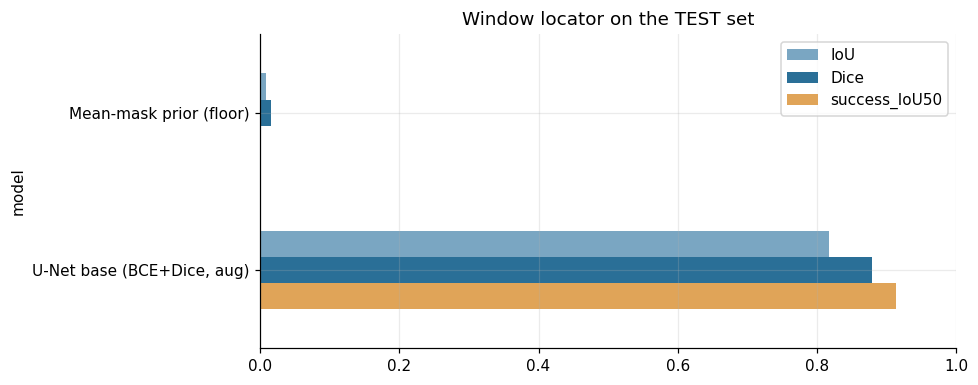

244

In [ ]:
prior = MASK256[SEG_TR].mean(0)
def prior_predict(X): return np.repeat(prior[None], len(X), 0)

seg_models = {'Mean-mask prior (floor)': prior_predict}
if RUN_SEG_ABLATIONS:
    t0 = time.time()
    p_bce, _ = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce', augment=True)
    p_noaug, _ = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce_dice', augment=False)
    seg_models['U-Net, BCE loss'] = p_bce
    seg_models['U-Net, no augmentation'] = p_noaug
    print(f'ablations trained in {time.time() - t0:.0f}s')
else:
    print('RAM-safe mode: skipping two optional U-Net ablation trainings; reusing the already-trained main U-Net.')
seg_models['U-Net base (BCE+Dice, aug)'] = unet_predict

rows = []
for n, fn in seg_models.items():
    pv = fn(Xs_va)
    sw = [(t, seg_summary(pv, MASK256[SEG_VA], t)['Dice']) for t in np.arange(.2, .81, .05)]
    thr = max(sw, key=lambda z: z[1])[0]
    r = seg_summary(fn(IMG256[test_idx]), MASK256[test_idx], thr); r.update(model=n, threshold=round(thr, 2)); rows.append(r)
SEG_COMP = pd.DataFrame(rows).set_index('model')[['threshold', 'IoU', 'Dice', 'success_IoU50', 'success_IoU75']]
display(SEG_COMP.round(3)); SEG_COMP.round(4).to_csv(WORK_DIR / 'segmentation_model_comparison.csv')
ax = SEG_COMP[['IoU', 'Dice', 'success_IoU50']].plot.barh(figsize=(9, 3.6), color=['#7aa6c2', '#2a6f97', '#e0a458']); ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_title('Window locator on the TEST set'); plt.tight_layout(); plt.show()
# Release temporary prediction arrays before the next project stage.
gc.collect()


### Results interpretation

The original experiment uses several measures:

- **Individual-digit accuracy** shows how often a single digit is recognised correctly.
- **Whole-number accuracy** checks whether all digits before the decimal point are correct.
- **Complete-reading accuracy** checks whether every digit in the meter reading is correct.

The original baseline comparison reported stronger digit-level results for Random Forest and a stronger complete-reading test result for SVM. These are historical results from the original full-display recognition experiment, not results from the new individual-digit CNN.

The improved CNN experiment in Part 7 reports its own held-out digit accuracy, macro precision, macro recall, macro F1, confusion matrix, confidence and complete-reading exact accuracy. Do not compare the two experiments as if they used identical labels or inputs.


# Part 5 · Testing the Complete Reading Process

This part checks how the stages work together, from a photograph to a meter reading:

**photo → U-Net (find display) → crop and straighten → orientation check → digit reader → reading**

Two things are measured for each reader:

- **Oracle crops:** the reader is given crops cut using the *supplied* display masks. This shows how good the reader is when the display is found perfectly.
- **Full pipeline:** the crop comes from the display area *predicted* by the U-Net. The gap between the two shows how much is lost because of display finding.

The timing of each stage is also reported.

This section tests the original CNN reader (all eight positions at once). The single-digit CNN from Part 7 is tested with the same function in Part 7.8. Random Forest is a comparison model and is not connected to this pipeline.

In [ ]:
# 5.1  The complete pipeline, built once and reused for every reader
def run_pipeline_on(i, reader_fn):
    """Photograph i -> reading. Returns the predicted digits, window IoU and the time spent in each stage."""
    t = {}
    t0 = time.perf_counter()
    im, gt, _ = read_aligned(ds.img_path[i], ds.mask_path[i])
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB); H, W = rgb.shape[:2]
    t['load'] = time.perf_counter() - t0

    t0 = time.perf_counter()
    prob = unet_predict(cv2.resize(rgb, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)[None])[0]
    pm = (cv2.resize(prob, (W, H), interpolation=cv2.INTER_LINEAR) > BEST_THR).astype(np.uint8)
    t['find display'] = time.perf_counter() - t0

    g = (gt > 127)
    iou = float((pm.astype(bool) & g).sum() / max((pm.astype(bool) | g).sum(), 1))
    t0 = time.perf_counter()
    geo = window_geometry(pm)
    if geo is None:
        return dict(pred=-np.ones(N_DIGITS, np.int64), found=False, iou=iou, t=t)
    crop = warp_window(rgb, geo)
    t['crop'] = time.perf_counter() - t0

    t0 = time.perf_counter()
    if needs_flip(crop[None])[0]:
        crop = np.ascontiguousarray(crop[::-1, ::-1])
    t['orientation'] = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = np.asarray(reader_fn(crop[None]))[0].astype(np.int64)
    t['read digits'] = time.perf_counter() - t0
    return dict(pred=pred, found=True, iou=iou, t=t)

def evaluate_pipeline(idx, reader_fn, label):
    idx = np.asarray(idx)
    out = [run_pipeline_on(i, reader_fn) for i in tqdm(idx, desc=label)]
    P = np.stack([o['pred'] for o in out]); Y = DIG[idx]
    oracle = digit_metrics(Y, np.asarray(reader_fn(CROPS_UP[idx])).astype(np.int64))
    full = digit_metrics(Y, P)
    stages = pd.DataFrame([o['t'] for o in out]).mean() * 1000
    return dict(label=label, oracle=oracle, full=full, found=float(np.mean([o['found'] for o in out])),
                iou=float(np.mean([o['iou'] for o in out])), ms=stages, ms_total=float(stages.sum()), pred=P, idx=idx)

def pipeline_table(*results):
    rows = {}
    for r in results:
        for kind, key in (('oracle crops', 'oracle'), ('full pipeline', 'full')):
            m = r[key]
            rows[f"{r['label']} | {kind}"] = {
                'Complete reading': f"{m['exact']:.1%}", 'Whole-number part': f"{m['m3_exact']:.1%}",
                'Single digits': f"{m['digit_acc']:.1%}", 'Within 1 m³': f"{m['within_1m3']:.1%}",
                'Display found': '-' if key == 'oracle' else f"{r['found']:.1%}",
                'Display IoU': '-' if key == 'oracle' else f"{r['iou']:.3f}",
                'Photos': m['n']}
    return pd.DataFrame(rows).T

In [ ]:
# 5.2  Test the ORIGINAL CNN reader (eight positions at once) on the held-out photographs
cnn_reader_fn = lambda X: READER_PREDICT(X).argmax(-1)
PIPE_CNN = evaluate_pipeline(R_test, cnn_reader_fn, 'Original CNN reader')

display(pipeline_table(PIPE_CNN))
print(f"\nTime per photograph (ms): total {PIPE_CNN['ms_total']:.0f}")
display(PIPE_CNN['ms'].round(1).to_frame('ms per photograph'))
drop = PIPE_CNN['oracle']['exact'] - PIPE_CNN['full']['exact']
print(f"\nComplete-reading accuracy lost because of display finding: {drop * 100:.1f} percentage points.")
pipeline_table(PIPE_CNN).to_csv(WORK_DIR / 'pipeline_original_cnn.csv')

Original CNN reader:   0%|          | 0/187 [00:00<?, ?it/s]

,Complete reading,Whole-number part,Single digits,Within 1 m³,Display found,Display IoU,Photos
Original CNN reader | oracle crops,0.0%,0.0%,35.2%,0.0%,-,-,187
Original CNN reader | full pipeline,0.0%,0.5%,34.9%,0.5%,99.5%,0.808,187



Time per photograph (ms): total 458


,ms per photograph
load,18.3
find display,174.6
crop,17.0
orientation,115.7
read digits,132.6



Complete-reading accuracy lost because of display finding: 0.0 percentage points.


### Part 6: Conclusion and Next Development Stage

The existing pipeline uses U-Net to locate the complete reading window, an orientation classifier to correct the crop, and a CNN that predicts the eight digit positions together.

The supplied masks identify the whole display window. They do not provide individual digit boxes or digit masks. The next stage therefore creates a digit box for each of the eight positions automatically, checks them automatically, and exports review sheets so that a person can spot-check them. A separate single-digit CNN is then trained and tested on the same held-out photographs as the models above.

No improvement in recognition accuracy should be claimed until that model has been trained and evaluated on the held-out photographs.

# Part 7 · Individual-Digit CNN

This stage keeps the U-Net display-window segmentation and the CNN project direction. It changes the digit-recognition unit from one full-display prediction to eight ordered, individually classified digit crops.

**Labels:** the dataset has display-window masks, not digit-level boxes. Each digit's label comes from the supplied meter `value` (five integer digits followed by three decimals). The boxes are generated automatically from the orientation-corrected display crops.

**Two kinds of box** are produced for every digit position:
- **`slot`** (default): the equal-width slot of the display for that position, with a small margin. It is consistent, and it is what the pipeline can reproduce on a new photograph.
- **`opencv`**: a tight box found with thresholding and contours inside the slot. It can be useful but sometimes locks onto a wheel edge or frame instead of the digit.

**Quality control (what is automatic and what is not).** The automatic check is weak: it only rejects photographs where a slot is blank. In the full dataset it rejected none, so `verified = 2` does not mean the boxes are correct.

| `verified` | Meaning |
|---|---|
| `1` | Checked by a person. |
| `2` | Passed the blank-slot test only (every slot has enough contrast to hold something). **Not** human-verified. |
| `0` | Failed the automatic check or not yet reviewed. Not used for training. |
| `-1` | Excluded by a person. |

Review sheets (green boxes, red labels) are exported so that a sample can be checked by eye. Set `ALLOW_AUTO_QA = False` in the configuration cell to train on `verified = 1` rows only.

Created 9664 digit boxes for 1208 photographs (box mode: slot).
Blank-slot check: 1208 photographs passed (verified=2), 0 flagged (verified=0). This check is weak, so look at the review sheets.
Annotation CSV: /content/outputs/digit_annotations/digit_annotations_review.csv
Saved 5 review sheets to /content/outputs/digit_annotations/review_sheets


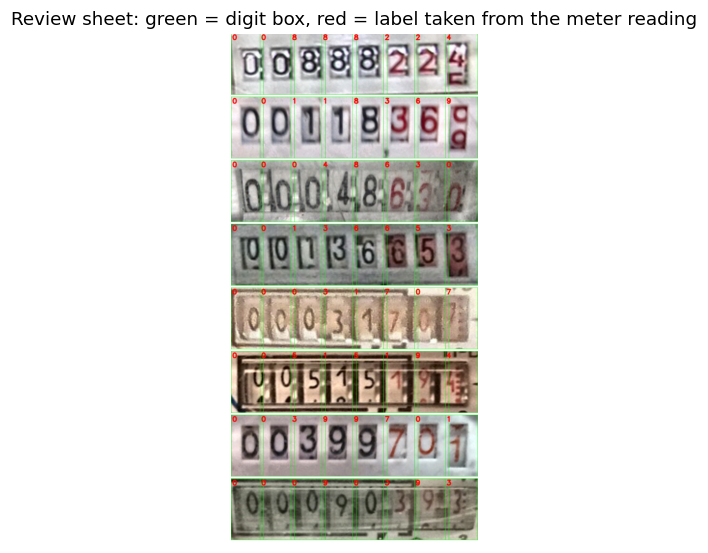

In [ ]:
# 7.1  Generate the digit boxes, quality-check them, and export review sheets
from pathlib import Path
import pandas as pd, cv2, numpy as np

ANNOT_DIR   = WORK_DIR / "digit_annotations"
DISPLAY_DIR = ANNOT_DIR / "display_crops"
SHEET_DIR   = ANNOT_DIR / "review_sheets"
for d in (DISPLAY_DIR, SHEET_DIR): d.mkdir(parents=True, exist_ok=True)

BOX_MODE        = 'slot'            # 'slot' (default) or 'opencv'
SLOT_MARGIN     = 2                 # pixels added each side of a slot
DIGIT_H, DIGIT_W = CROP_H, CROP_W // N_DIGITS     # every digit is resized to 64 x 32
QA_MIN_CONTRAST = 12.0              # grey-level std a slot needs to be considered "contains a digit"

def slot_box(position, width=CROP_W, height=CROP_H, margin=SLOT_MARGIN):
    x0 = round(position * width / N_DIGITS); x1 = round((position + 1) * width / N_DIGITS)
    return max(0, x0 - margin), 0, min(width, x1 + margin), height

def propose_digit_box(crop, position, width=CROP_W, height=CROP_H):
    """Tight box from thresholding + contours inside the slot (falls back to the slot)."""
    x0 = round(position * width / N_DIGITS); x1 = round((position + 1) * width / N_DIGITS)
    patch = crop[4:height - 4, x0:x1]
    gray = cv2.GaussianBlur(cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY), (3, 3), 0)
    candidates = []
    for mode in (cv2.THRESH_BINARY_INV, cv2.THRESH_BINARY):
        _, binary = cv2.threshold(gray, 0, 255, mode + cv2.THRESH_OTSU)
        binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
        for contour in cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            x, y, w, h = cv2.boundingRect(contour); area = cv2.contourArea(contour)
            if area >= 3 and h >= 8 and w >= 3: candidates.append((area, x, y, w, h))
    if candidates:
        _, x, y, w, h = max(candidates, key=lambda z: z[0])
        px, py = max(2, int(w * .18)), max(2, int(h * .12))
        lx, rx = max(0, x - px), min(patch.shape[1], x + w + px)
        ty, by = max(0, y - py), min(patch.shape[0], y + h + py)
        if rx - lx < 7: lx, rx = 0, patch.shape[1]
        if by - ty < 12: ty, by = 0, patch.shape[0]
        return x0 + lx, 4 + ty, x0 + rx, 4 + by, "opencv"
    return x0, 0, x1, height, "slot_fallback"

def digit_boxes_for_crop(crop, mode=None):
    """Eight (x1, y1, x2, y2) boxes for one display crop. Used for training AND for new photographs."""
    mode = mode or BOX_MODE
    if mode == 'slot':
        return [slot_box(p) for p in range(N_DIGITS)]
    return [propose_digit_box(crop, p)[:4] for p in range(N_DIGITS)]

def cut_digits(crop, boxes):
    return np.stack([cv2.resize(crop[y1:y2, x1:x2], (DIGIT_W, DIGIT_H), interpolation=cv2.INTER_AREA) for x1, y1, x2, y2 in boxes])

rows = []
for i in np.where(ds.reader_ok.values)[0]:
    crop = np.asarray(CROPS_DIGIT_UP[i])
    crop_name = f"{Path(str(ds.photo_name.iloc[i])).stem}.png"
    cv2.imwrite(str(DISPLAY_DIR / crop_name), cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))
    per_pos, contrasts = [], []
    for pos in range(N_DIGITS):
        sx1, sy1, sx2, sy2 = slot_box(pos)
        cx1, cy1, cx2, cy2, method = propose_digit_box(crop, pos)
        contrast = float(cv2.cvtColor(crop[sy1:sy2, sx1:sx2], cv2.COLOR_RGB2GRAY).std())
        contrasts.append(contrast)
        x1, y1, x2, y2 = (sx1, sy1, sx2, sy2) if BOX_MODE == 'slot' else (cx1, cy1, cx2, cy2)
        per_pos.append({"photo_name": ds.photo_name.iloc[i], "value": float(ds.value.iloc[i]), "digit_position": pos,
                        "label": int(DIG[i, pos]), "x1": x1, "y1": y1, "x2": x2, "y2": y2, "box_mode": BOX_MODE,
                        "slot_x1": sx1, "slot_x2": sx2, "opencv_x1": cx1, "opencv_y1": cy1, "opencv_x2": cx2, "opencv_y2": cy2,
                        "opencv_method": method, "contrast": round(contrast, 2), "crop_path": f"display_crops/{crop_name}"})
    photo_ok = min(contrasts) >= QA_MIN_CONTRAST          # all eight slots must look like they hold a digit
    for r in per_pos:
        r["verified"] = 2 if photo_ok else 0
        r["notes"] = "" if photo_ok else "low-contrast slot: review"
    rows.extend(per_pos)

ANNOT_CSV = ANNOT_DIR / "digit_annotations_review.csv"
annot = pd.DataFrame(rows); annot.to_csv(ANNOT_CSV, index=False)
n_photos = annot.photo_name.nunique(); n_pass = annot[annot.verified == 2].photo_name.nunique()
print(f"Created {len(annot)} digit boxes for {n_photos} photographs (box mode: {BOX_MODE}).")
print(f"Blank-slot check: {n_pass} photographs passed (verified=2), {n_photos - n_pass} flagged (verified=0). This check is weak, so look at the review sheets.")
print("Annotation CSV:", ANNOT_CSV)

# Review sheets: green boxes and red labels on enlarged display crops
def draw_review_sheet(photo_names, path, scale=3):
    strips = []
    for name in photo_names:
        g = annot[annot.photo_name == name].sort_values("digit_position")
        i = int(ds.index[ds.photo_name == name][0])
        big = cv2.cvtColor(cv2.resize(np.asarray(CROPS_DIGIT_UP[i]), None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC), cv2.COLOR_RGB2BGR)
        for r in g.itertuples():
            cv2.rectangle(big, (r.x1 * scale, r.y1 * scale), (r.x2 * scale - 1, r.y2 * scale - 1), (0, 255, 0), 1)
            cv2.putText(big, str(r.label), (r.x1 * scale + 4, r.y1 * scale + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2, cv2.LINE_AA)
        strips.append(big)
        strips.append(np.full((6, big.shape[1], 3), 255, np.uint8))
    sheet = np.vstack(strips); cv2.imwrite(str(path), sheet); return sheet

rng = np.random.default_rng(SEED)
names = annot.photo_name.unique()
review_first = list(annot[annot.verified == 0].photo_name.unique()[:8])          # failed the check: look at these first
random_pick = list(rng.choice(names, size=min(40, len(names)), replace=False))
sheet_lists = ([review_first] if review_first else []) + [random_pick[k:k + 8] for k in range(0, len(random_pick), 8)]
sheets = [draw_review_sheet(lst, SHEET_DIR / f"review_sheet_{k + 1:02d}.jpg") for k, lst in enumerate(sheet_lists)]
print(f"Saved {len(sheets)} review sheets to {SHEET_DIR}")
plt.figure(figsize=(9, 6)); plt.imshow(cv2.cvtColor(sheets[0], cv2.COLOR_BGR2RGB)); plt.axis('off')
plt.title("Review sheet: green = digit box, red = label taken from the meter reading"); plt.show()

## 7.2 Checking the digit boxes

The `label` values come from the supplied meter `value`, so they are the true digits **provided the box sits on the right wheel**. The review sheets above show exactly that: each green box should contain the digit printed in red at its top-left corner.

**Recommended check (about five minutes):** open two or three of the review sheets in `digit_annotations/review_sheets/`. If almost all boxes sit on the right digits, the automatic boxes are fine for training. If a photograph looks wrong, set `verified = -1` for it in `digit_annotations_review.csv`; set `verified = 1` for photographs you have checked yourself.

Rows with `verified = 0` (failed the automatic contrast check) are never used for training.

Digit crops: (9664, 64, 32, 3) | photographs: 1208
Status of the rows used  (1 = checked by a person, 2 = automatic check only): {2: 9664}
Label counts: {0: 3363, 1: 989, 2: 764, 3: 765, 4: 693, 5: 665, 6: 626, 7: 611, 8: 608, 9: 580}


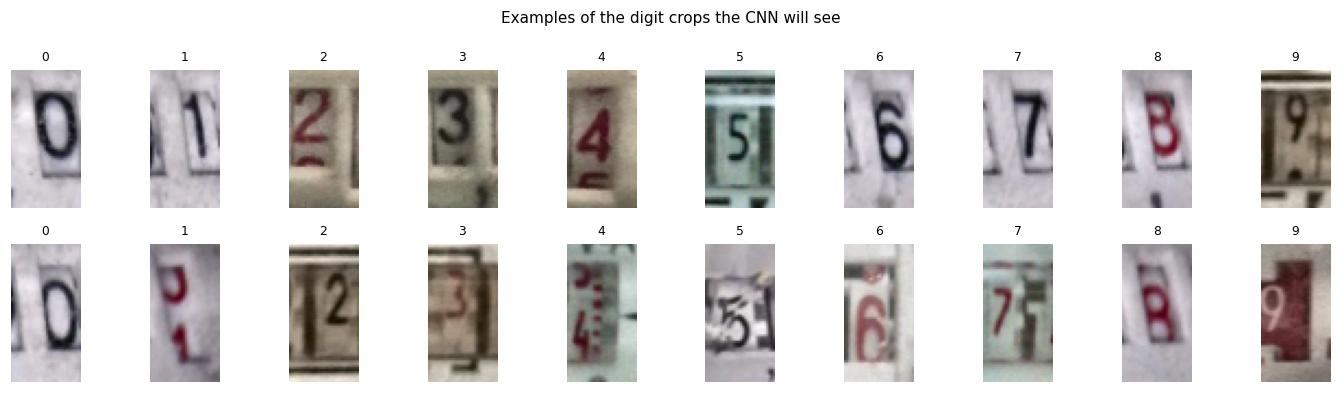

In [ ]:
# 7.3  Load the digit crops (only rows allowed by the quality settings)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
import json

ann = pd.read_csv(ANNOT_CSV)                          # re-read, so edits made by hand are respected
allowed = {1, 2} if ALLOW_AUTO_QA else {1}
ann = ann[ann["verified"].isin(allowed)].copy()
full = ann.groupby("photo_name").digit_position.nunique()
ann = ann[ann.photo_name.isin(full[full == N_DIGITS].index)]          # keep photographs with all eight positions
if ann.empty:
    raise RuntimeError("No usable annotations. Check ALLOW_AUTO_QA and the verified column.")

name_to_idx = {str(n): i for i, n in enumerate(ds.photo_name)}
Xs_, ys_, gs_, ns_, ps_, sp_, vs_ = [], [], [], [], [], [], []
for r in ann.sort_values(["photo_name", "digit_position"]).itertuples():
    i = name_to_idx[str(r.photo_name)]
    x1, y1, x2, y2 = int(r.x1), int(r.y1), int(r.x2), int(r.y2)
    if x2 <= x1 or y2 <= y1: continue
    patch = np.asarray(CROPS_DIGIT_UP[i])[max(0, y1):y2, max(0, x1):x2]
    if patch.size == 0: continue
    Xs_.append(cv2.resize(patch, (DIGIT_W, DIGIT_H), interpolation=cv2.INTER_AREA))
    ys_.append(int(r.label)); gs_.append(str(ds.group.iloc[i])); ns_.append(str(r.photo_name))
    ps_.append(int(r.digit_position)); sp_.append(ds.split.iloc[i]); vs_.append(int(r.verified))

X_digit = np.asarray(Xs_, dtype=np.uint8); y_digit = np.asarray(ys_, dtype=np.int64)
g_digit = np.asarray(gs_); names_digit = np.asarray(ns_); pos_digit = np.asarray(ps_); split_digit = np.asarray(sp_)
print("Digit crops:", X_digit.shape, "| photographs:", len(set(ns_)))
print("Status of the rows used  (1 = checked by a person, 2 = automatic check only):", pd.Series(vs_).value_counts().to_dict())
print("Label counts:", pd.Series(y_digit).value_counts().sort_index().to_dict())
fig, ax = plt.subplots(2, 10, figsize=(13, 3.6))
for d in range(10):
    ids = np.where(y_digit == d)[0][:2]
    for k in range(2):
        ax[k, d].axis('off')
        if k < len(ids): ax[k, d].imshow(X_digit[ids[k]]); ax[k, d].set_title(str(d), fontsize=8)
plt.suptitle('Examples of the digit crops the CNN will see', fontsize=10); plt.tight_layout(); plt.show()

In [ ]:
# 7.4  Split: the SAME held-out test photographs as Parts 3-5, so results can be compared directly
test_digit_ids = np.where(split_digit == 'test')[0]
dev_digit_ids  = np.where(split_digit == 'dev')[0]
inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED + 1)
tr_l, va_l = next(inner.split(dev_digit_ids, groups=g_digit[dev_digit_ids]))
train_digit_ids, val_digit_ids = dev_digit_ids[tr_l], dev_digit_ids[va_l]

for nm, ids in (('Train', train_digit_ids), ('Validation', val_digit_ids), ('Test', test_digit_ids)):
    print(f"{nm:10s}: {len(ids):5d} digit crops | {len(set(names_digit[ids])):4d} photographs | {len(set(g_digit[ids])):4d} groups")
assert not (set(g_digit[train_digit_ids]) & set(g_digit[test_digit_ids])), "group leakage between train and test"
assert not (set(g_digit[val_digit_ids]) & set(g_digit[test_digit_ids])), "group leakage between validation and test"

Train     :  6944 digit crops |  868 photographs |  866 groups
Validation:  1224 digit crops |  153 photographs |  153 groups
Test      :  1496 digit crops |  187 photographs |  187 groups


Epoch 1/40
109/109 - 16s - 144ms/step - accuracy: 0.3622 - loss: 1.8927 - val_accuracy: 0.1103 - val_loss: 2.2430 - learning_rate: 0.0010
Epoch 2/40
109/109 - 3s - 23ms/step - accuracy: 0.5939 - loss: 1.1971 - val_accuracy: 0.3399 - val_loss: 1.8673 - learning_rate: 0.0010
Epoch 3/40
109/109 - 3s - 27ms/step - accuracy: 0.7540 - loss: 0.7564 - val_accuracy: 0.6650 - val_loss: 1.0644 - learning_rate: 0.0010
Epoch 4/40
109/109 - 3s - 25ms/step - accuracy: 0.8302 - loss: 0.5343 - val_accuracy: 0.8562 - val_loss: 0.5495 - learning_rate: 0.0010
Epoch 5/40
109/109 - 3s - 23ms/step - accuracy: 0.8694 - loss: 0.4308 - val_accuracy: 0.8856 - val_loss: 0.3702 - learning_rate: 0.0010
Epoch 6/40
109/109 - 2s - 23ms/step - accuracy: 0.8939 - loss: 0.3492 - val_accuracy: 0.9044 - val_loss: 0.3094 - learning_rate: 0.0010
Epoch 7/40
109/109 - 2s - 23ms/step - accuracy: 0.9067 - loss: 0.2974 - val_accuracy: 0.9240 - val_loss: 0.2804 - learning_rate: 0.0010
Epoch 8/40
109/109 - 3s - 28ms/step - accuracy

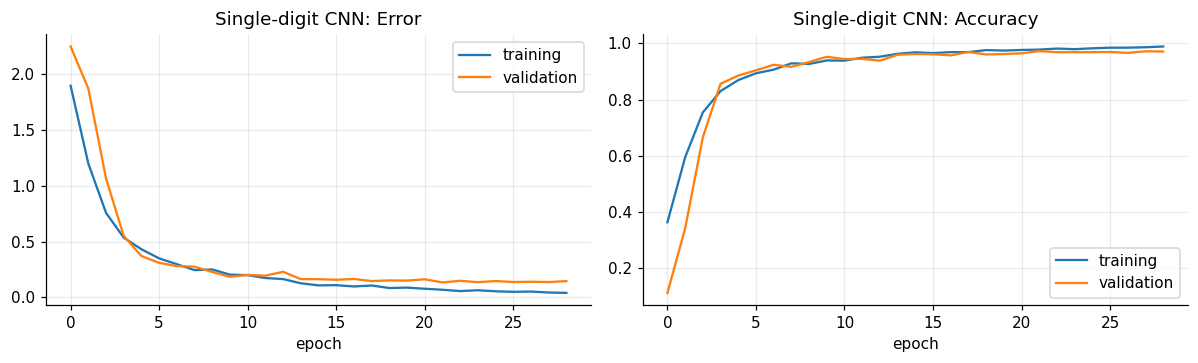

In [ ]:
# 7.5  Build and train the dedicated 0-9 CNN (augmentation is applied to training data only)
import tensorflow as tf
from tensorflow.keras import layers as L

def build_digit_cnn():
    inp = L.Input((DIGIT_H, DIGIT_W, 3))
    z = L.Rescaling(1 / 255.0)(inp)
    z = L.RandomRotation(0.03)(z); z = L.RandomTranslation(0.06, 0.06)(z)
    z = L.RandomZoom(0.08)(z); z = L.RandomContrast(0.15)(z)          # active only while training
    for filters in (32, 64, 128):
        z = L.Conv2D(filters, 3, padding="same", use_bias=False)(z)
        z = L.BatchNormalization()(z); z = L.Activation("relu")(z)
        z = L.Conv2D(filters, 3, padding="same", activation="relu")(z)
        z = L.MaxPooling2D()(z)
    z = L.Dropout(0.35)(L.Flatten()(z))
    z = L.Dropout(0.25)(L.Dense(128, activation="relu")(z))
    return tf.keras.Model(inp, L.Dense(10, activation="softmax")(z), name="single_digit_cnn")

tf.keras.utils.set_random_seed(SEED)
DIGIT_CNN = build_digit_cnn()
DIGIT_CNN.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)]
t0 = time.time()
history_digit = DIGIT_CNN.fit(
    X_digit[train_digit_ids].astype(np.float32), y_digit[train_digit_ids],
    validation_data=(X_digit[val_digit_ids].astype(np.float32), y_digit[val_digit_ids]),
    epochs=DIGIT_EPOCHS, batch_size=64, callbacks=callbacks, verbose=2)
print(f"Trained in {time.time() - t0:.0f}s")
DIGIT_MODEL_PATH = WORK_DIR / "single_digit_cnn.keras"
DIGIT_CNN.save(DIGIT_MODEL_PATH); print("Saved:", DIGIT_MODEL_PATH)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, (k, t) in zip(ax, (("loss", "Error"), ("accuracy", "Accuracy"))):
    a.plot(history_digit.history[k], label="training"); a.plot(history_digit.history["val_" + k], label="validation")
    a.set_title(f"Single-digit CNN: {t}"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

{
  "digit_accuracy": 0.9485294117647058,
  "macro_precision": 0.9423038628411554,
  "macro_recall": 0.9467932815404257,
  "macro_f1": 0.9443365548116361,
  "mean_confidence": 0.9720159769058228,
  "test_digit_crops": 1496,
  "test_photographs": 187,
  "labels": "auto-QA boxes"
}
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       517
           1       0.95      0.92      0.93       154
           2       0.90      0.92      0.91       109
           3       0.96      0.96      0.96       123
           4       0.89      0.94      0.91       108
           5       0.95      0.98      0.96       108
           6       0.97      0.93      0.95        97
           7       0.91      0.94      0.93        90
           8       0.98      0.98      0.98        83
           9       0.95      0.95      0.95       107

    accuracy                           0.95      1496
   macro avg       0.94      0.95      0.94      1496
weighted avg   

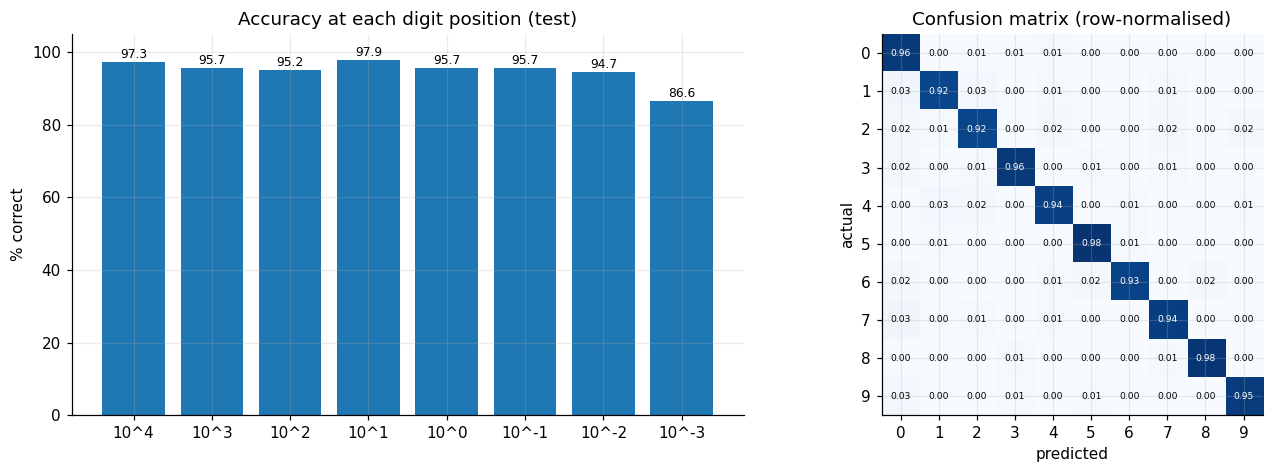

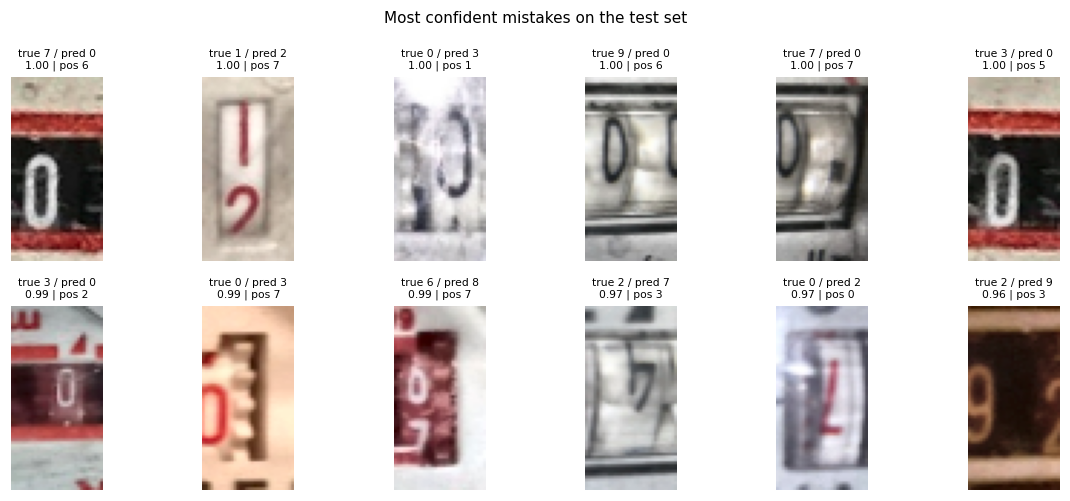

280

In [ ]:
# 7.6  Held-out digit metrics, per-position accuracy, confusion matrix and the most confident mistakes
test_prob = DIGIT_CNN.predict(X_digit[test_digit_ids].astype(np.float32), verbose=0)
test_pred, test_conf, test_actual = test_prob.argmax(1), test_prob.max(1), y_digit[test_digit_ids]

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(test_actual, test_pred, average="macro", zero_division=0)
digit_metrics_new = {"digit_accuracy": float(accuracy_score(test_actual, test_pred)), "macro_precision": float(macro_p),
                     "macro_recall": float(macro_r), "macro_f1": float(macro_f1), "mean_confidence": float(test_conf.mean()),
                     "test_digit_crops": int(len(test_digit_ids)), "test_photographs": int(len(set(names_digit[test_digit_ids]))),
                     "labels": "auto-QA boxes" if ALLOW_AUTO_QA else "person-verified boxes only"}
print(json.dumps(digit_metrics_new, indent=2))
print(classification_report(test_actual, test_pred, labels=list(range(10)), zero_division=0))

cm_digit = confusion_matrix(test_actual, test_pred, labels=list(range(10)))
per_pos = [(test_pred[pos_digit[test_digit_ids] == p] == test_actual[pos_digit[test_digit_ids] == p]).mean() * 100 for p in range(N_DIGITS)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
b = ax[0].bar(POS_LABELS, per_pos); ax[0].set_ylim(0, 105); ax[0].set_title("Accuracy at each digit position (test)"); ax[0].set_ylabel("% correct")
for bar, v in zip(b, per_pos): ax[0].text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.1f}", ha="center", fontsize=8)
cmn = cm_digit / np.maximum(cm_digit.sum(1, keepdims=True), 1)
im = ax[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax[1].set_title("Confusion matrix (row-normalised)")
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("actual"); ax[1].set_xticks(range(10)); ax[1].set_yticks(range(10))
for i in range(10):
    for j in range(10): ax[1].text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > .5 else "black")
plt.tight_layout(); plt.show()

# Most confident mistakes: check these first. They are either genuine model errors or box/label problems.
wrong = np.where(test_pred != test_actual)[0]
wrong = wrong[np.argsort(-test_conf[wrong])][:12]
if len(wrong):
    fig, ax = plt.subplots(2, 6, figsize=(11, 4.6)); ax = ax.ravel()
    for a in ax: a.axis('off')
    for a, k in zip(ax, wrong):
        gi = test_digit_ids[k]; a.imshow(X_digit[gi])
        a.set_title(f"true {test_actual[k]} / pred {test_pred[k]}\n{test_conf[k]:.2f} | pos {pos_digit[gi]}", fontsize=7)
    plt.suptitle("Most confident mistakes on the test set", fontsize=10); plt.tight_layout(); plt.show()

pd.DataFrame(cm_digit).rename_axis("actual").to_csv(WORK_DIR / "digit_confusion_matrix.csv")
pd.DataFrame({"photo_name": names_digit[test_digit_ids], "position": pos_digit[test_digit_ids], "actual": test_actual,
              "predicted": test_pred, "confidence": test_conf, "correct": test_pred == test_actual}).to_csv(WORK_DIR / "digit_test_predictions.csv", index=False)
(WORK_DIR / "digit_metrics.json").write_text(json.dumps(digit_metrics_new, indent=2))

In [ ]:
# 7.7  Complete eight-digit readings on the held-out photographs, compared with the Part 4 models on the SAME photographs
tdf = pd.DataFrame({"photo_name": names_digit[test_digit_ids], "position": pos_digit[test_digit_ids], "actual": test_actual, "predicted": test_pred})
reading_rows = []
for name, g in tdf.groupby("photo_name"):
    g = g.sort_values("position")
    if g.position.tolist() != list(range(N_DIGITS)): continue
    a, p = "".join(map(str, g.actual)), "".join(map(str, g.predicted))
    reading_rows.append({"photo_name": name, "predicted": p[:5] + "." + p[5:], "actual": a[:5] + "." + a[5:], "exact_reading": a == p,
                         "whole_number_ok": a[:5] == p[:5], "wrong_digits": sum(x != y for x, y in zip(a, p))})
reading_eval = pd.DataFrame(reading_rows)
reading_eval.to_csv(WORK_DIR / "complete_reading_test.csv", index=False)
print(f"Photographs evaluated: {len(reading_eval)}")
print(f"Complete-reading accuracy (single-digit CNN): {reading_eval.exact_reading.mean():.1%}")
print(f"Whole-number part correct: {reading_eval.whole_number_ok.mean():.1%}")
print("Wrong digits per photograph:", reading_eval.wrong_digits.value_counts().sort_index().to_dict())
display(reading_eval[~reading_eval.exact_reading].head(15))

# Same photographs, same split: Part 4 models vs the single-digit CNN
same = np.isin(ds.photo_name.values[R_test].astype(str), reading_eval.photo_name.values)
cmp_rows = {}
for nm, rr in RESULTS.items():
    P, Y = rr["test_pred"][same], DIG[R_test][same]
    cmp_rows[nm] = {"complete reading": (P == Y).all(1).mean(), "whole-number part": (P[:, :5] == Y[:, :5]).all(1).mean(), "single digits": (P == Y).mean()}
cmp_rows["Single-digit CNN (Part 7)"] = {"complete reading": reading_eval.exact_reading.mean(), "whole-number part": reading_eval.whole_number_ok.mean(),
                                         "single digits": digit_metrics_new["digit_accuracy"]}
HEAD2HEAD = pd.DataFrame(cmp_rows).T
display((HEAD2HEAD * 100).round(1).astype(str) + " %")
HEAD2HEAD.round(4).to_csv(WORK_DIR / "head_to_head_same_photographs.csv")
print(f"All rows above use the same {int(same.sum())} held-out photographs (oracle crops from the supplied masks).")

Photographs evaluated: 187
Complete-reading accuracy (single-digit CNN): 78.6%
Whole-number part correct: 91.4%
Wrong digits per photograph: {0: 147, 1: 29, 2: 4, 3: 2, 6: 3, 8: 2}


,photo_name,predicted,actual,exact_reading,whole_number_ok,wrong_digits
0,id_1007_value_60_219.jpg,44407.003,00060.219,False,False,8
1,id_1013_value_797_523.jpg,00797.527,00797.523,False,True,1
2,id_1020_value_61_941.jpg,00061.942,00061.941,False,True,1
12,id_1066_value_290_429.jpg,00290.420,00290.429,False,True,1
20,id_1089_value_10_955.jpg,00019.955,00010.955,False,False,1
25,id_1102_value_920_047.jpg,00092.047,00920.047,False,False,3
28,id_1134_value_366_995.jpg,00366.991,00366.995,False,True,1
38,id_1183_value_360_981.jpg,00360.982,00360.981,False,True,1
40,id_1197_value_974_68.jpg,00974.880,00974.680,False,True,1
49,id_1230_value_424_297.jpg,26276.900,00424.297,False,False,8


,complete reading,whole-number part,single digits
CNN base (aug + dropout + L2),0.0 %,0.0 %,35.2 %
Single-digit CNN (Part 7),78.6 %,91.4 %,94.9 %


All rows above use the same 187 held-out photographs (oracle crops from the supplied masks).


In [ ]:
# 7.8  End-to-end test with the single-digit CNN (photo -> U-Net -> crop -> orientation -> digit CNN -> reading)
def digit_reader_fn(crops):
    crops = np.asarray(crops)
    slots = np.concatenate([cut_digits(c, digit_boxes_for_crop(c)) for c in crops])
    probs = DIGIT_CNN.predict(slots.astype(np.float32), batch_size=256, verbose=0)
    return probs.argmax(1).reshape(len(crops), N_DIGITS)

PIPE_DIGIT = evaluate_pipeline(R_test, digit_reader_fn, 'Single-digit CNN')
display(pipeline_table(PIPE_CNN, PIPE_DIGIT))
timing = pd.DataFrame({"Original CNN reader": PIPE_CNN["ms"], "Single-digit CNN": PIPE_DIGIT["ms"]}).round(1)
timing.loc["TOTAL"] = timing.sum()
print("\nTime per photograph (ms):"); display(timing)
pipeline_table(PIPE_CNN, PIPE_DIGIT).to_csv(WORK_DIR / "pipeline_comparison.csv")
timing.to_csv(WORK_DIR / "pipeline_timing.csv")

wrong_photos = [(ds.photo_name[i], fmt_reading(DIG[i]), fmt_reading(p)) for i, p in zip(PIPE_DIGIT["idx"], PIPE_DIGIT["pred"]) if (p != DIG[i]).any()]
print(f"\nPhotographs read incorrectly by the full pipeline: {len(wrong_photos)} of {len(PIPE_DIGIT['idx'])}")
display(pd.DataFrame(wrong_photos, columns=["photo", "actual", "predicted"]).head(15))

Single-digit CNN:   0%|          | 0/187 [00:00<?, ?it/s]

,Complete reading,Whole-number part,Single digits,Within 1 m³,Display found,Display IoU,Photos
Original CNN reader | oracle crops,0.0%,0.0%,35.2%,0.0%,-,-,187
Original CNN reader | full pipeline,0.0%,0.5%,34.9%,0.5%,99.5%,0.808,187
Single-digit CNN | oracle crops,78.6%,91.4%,94.9%,91.4%,-,-,187
Single-digit CNN | full pipeline,64.2%,78.1%,84.4%,78.1%,99.5%,0.808,187



Time per photograph (ms):


,Original CNN reader,Single-digit CNN
load,18.3,17.3
find display,174.6,114.7
crop,17.0,16.5
orientation,115.7,94.6
read digits,132.6,98.4
TOTAL,458.2,341.5



Photographs read incorrectly by the full pipeline: 67 of 187


,photo,actual,predicted
0,id_807_value_149_848.jpg,00149.848,10019.441
1,id_737_value_119_002.jpg,00119.002,00119.005
2,id_1102_value_920_047.jpg,00920.047,10920.047
3,id_1050_value_60_509.jpg,00060.509,11444.111
4,id_565_value_248_164.jpg,00248.164,08212.070
5,id_1213_value_126_175.jpg,00126.175,00126.172
6,id_1198_value_46_895.jpg,00046.895,00046.857
7,id_135_value_127_529.jpg,00127.529,00421.452
8,id_342_value_160_019.jpg,00160.019,00560.049
9,id_644_value_233_386.jpg,00233.386,00233.388


## 7.9 Interpretation and limitations

Report the numbers from the cells above separately:

- **Single-digit accuracy, macro precision/recall/F1 and the confusion matrix** (7.6): how well one digit is recognised.
- **Complete-reading accuracy** (7.7): all eight positions must be correct, so it is always lower than single-digit accuracy.
- **Head-to-head table** (7.7): the Part 4 models and the single-digit CNN, on the same photographs, with crops cut from the supplied masks.
- **Full pipeline** (7.8): what a user would actually get from a photograph, including mistakes made while finding the display.

**Limitations to state**
- The digit labels come from the supplied meter readings. The digit **boxes** are automatic (equal slots) and were only checked by eye on sample sheets unless `verified = 1` was set by hand.
- Wheels that are part-way between two digits (common in the decimal positions) are genuinely ambiguous; the label is the reading the meter reports, which may not match what is visible.
- Photographs of meters with a zero decimal part were excluded from digit reading, because those meters may not show all eight digits.
- The orientation correction relies on red decimal wheels for its training labels, so it is less certain for meters without them.
- The test photographs were used once. If the model or settings are changed after looking at test errors, a new independent test set is needed before making a final performance claim.

In [ ]:
# 7.10  Save the results to Google Drive so they survive a Colab disconnect
try:
    unet_predict.model.save(WORK_DIR / "unet_window_locator.keras")
    orient_predict.model.save(WORK_DIR / "orientation_cnn.keras")
    READER_PREDICT.model.save(WORK_DIR / "full_display_cnn_reader.keras")
except Exception as e:
    print("Could not save one of the models:", str(e)[:100])

if IN_COLAB and os.path.ismount('/content/drive'):
    DRIVE_OUT.mkdir(parents=True, exist_ok=True)
    shutil.copytree(WORK_DIR, DRIVE_OUT, dirs_exist_ok=True)
    print("Saved everything in", WORK_DIR, "to", DRIVE_OUT)
else:
    print("Drive is not mounted; results are only in", WORK_DIR)
print("Files:", sorted(p.name for p in WORK_DIR.iterdir())[:25])

Saved everything in /content/outputs to /content/drive/MyDrive/water_meter_outputs
Files: ['clean_dataset.csv', 'cleaning_log.csv', 'complete_reading_test.csv', 'digit_annotations', 'digit_confusion_matrix.csv', 'digit_metrics.json', 'digit_test_predictions.csv', 'full_display_cnn_reader.keras', 'head_to_head_same_photographs.csv', 'orientation_cnn.keras', 'pipeline_comparison.csv', 'pipeline_original_cnn.csv', 'pipeline_timing.csv', 'reader_model_comparison.csv', 'segmentation_model_comparison.csv', 'single_digit_cnn.keras', 'unet_window_locator.keras']
